In [3]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [4]:
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/Mašinsko učenje/Zadatak 1.3/Dirty_BankChurners_dataset.csv')


In [5]:
df.head()


,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2,Account_Status,Last_Login_Days
0,768805383.0X,Existing Customer,45.0,M,3.0,High School,Married,$60K - $80K,Bule,39.0,...,687017,NaN,1144.0,42.0X,1.625,0.061,9.3448e-05,0.99991,Pending,219
1,818770008.0,Existing Customer,49.0,F,5.0,Graduate,Single,Less than $40K,Blue,44.0,...,815553,NaN,1291.0,624162,3.714#,0.105,5.6861e-05,0.99994,Inactive,98
2,713982108.0,Existing Customer,NaN,M,3.0,Graduate,Married,$80K - $120K,Blue,-36.0,...,3418.0,2.594,1887.0,20.0,2.333,0.0X,2.1081e-05,663520,Inactive,303
3,769911858.0,Existing Customer,-40.0,F,4.0,High School,Unknown,Less than $40K_NOT_VALID,Blue,34.0#,...,796.0,1.405,1171.0,20.0,2.333,0.76,0.00013366,0.99987,Active,115
4,709106358.0#,Existing Customer,NaN,M,3.0,Uneducated,Marreid,$K00 $-68K,Blue,838122,...,4716.0,2.175,-816.0,28.0,2.5,0.0*,680369,0.99998,Pending,1


In [6]:
print("Nazivi kolona:")
for col in df.columns:
    print(col)


Nazivi kolona:
CLIENTNUM
Attrition_Flag
Customer_Age
Gender
Dependent_count
Education_Level
Marital_Status
Income_Category
Card_Category
Months_on_book
Total_Relationship_Count
Months_Inactive_12_mon
Contacts_Count_12_mon
Credit_Limit
Total_Revolving_Bal
Avg_Open_To_Buy
Total_Amt_Chng_Q4_Q1
Total_Trans_Amt
Total_Trans_Ct
Total_Ct_Chng_Q4_Q1
Avg_Utilization_Ratio
Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1
Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
Account_Status
Last_Login_Days


In [7]:
print("Tipovi podataka po kolonama:")
df.dtypes


Tipovi podataka po kolonama:


,0
CLIENTNUM,object
Attrition_Flag,object
Customer_Age,object
Gender,object
Dependent_count,object
Education_Level,object
Marital_Status,object
Income_Category,object
Card_Category,object
Months_on_book,object


In [8]:
df['Last_Login_Days'].dtype


dtype('int64')

In [9]:
df['Last_Login_Days'].describe()


,Last_Login_Days
count,10127.000000
mean,183.607781
std,106.048092
min,1.000000
25%,92.000000
50%,185.000000
75%,276.000000
max,365.000000


In [10]:
mean_val = df['Last_Login_Days'].mean()
median_val = df['Last_Login_Days'].median()
std_val = df['Last_Login_Days'].std()
min_val = df['Last_Login_Days'].min()
max_val = df['Last_Login_Days'].max()

mean_val, median_val, std_val, min_val, max_val


(np.float64(183.60778117902638), 185.0, 106.04809247191122, 1, 365)

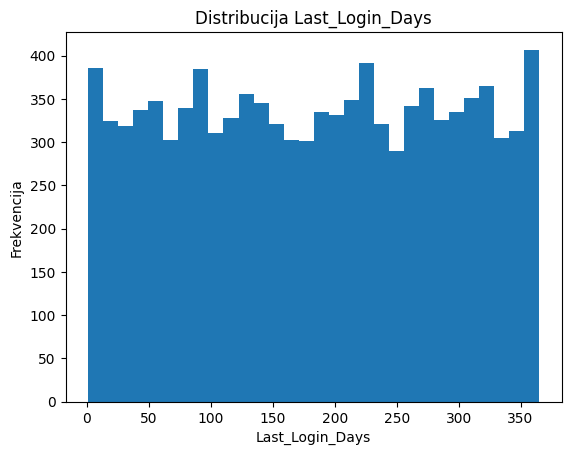

In [11]:
import matplotlib.pyplot as plt

plt.figure()
plt.hist(df['Last_Login_Days'], bins=30)
plt.title('Distribucija Last_Login_Days')
plt.xlabel('Last_Login_Days')
plt.ylabel('Frekvencija')
plt.show()


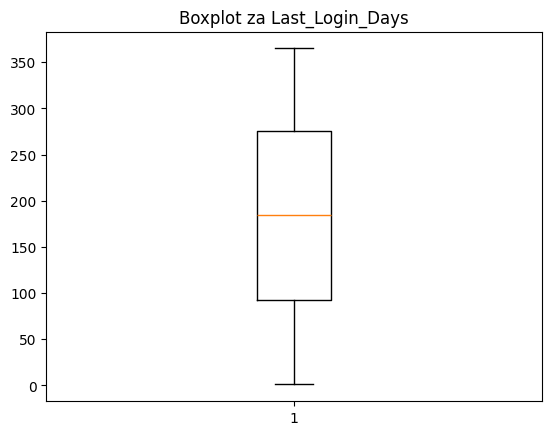

In [12]:
plt.figure()
plt.boxplot(df['Last_Login_Days'])
plt.title('Boxplot za Last_Login_Days')
plt.show()


In [13]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 25 columns):
 #   Column                                                                                                                              Non-Null Count  Dtype 
---  ------                                                                                                                              --------------  ----- 
 0   CLIENTNUM                                                                                                                           9788 non-null   object
 1   Attrition_Flag                                                                                                                      10127 non-null  object
 2   Customer_Age                                                                                                                        9853 non-null   object
 3   Gender                                                                                

**Kolona Attrition_Flag**

In [14]:
df["Attrition_Flag"].value_counts(dropna=False)


,count
Attrition_Flag,
Existing Customer,6788
Attrited Customer,1286
Existing Customer_UNKNOWN,238
Existing Customer_NOT_VALID,226
Existing Customer_RANDOM_TEXT,221
...,...
EmCstsigtou xeinr,1
EonmCgtsxsiti eur,1
EiusimsgtxoCe ntr,1


In [15]:
import pandas as pd
from difflib import get_close_matches

valid_targets = ['Existing Customer', 'Attrited Customer']

def clean_target_variable(text):
    if pd.isna(text):
        return "Unknown"

    text = str(text).strip()


    if 'Existing' in text:
        return 'Existing Customer'
    if 'Attrited' in text:
        return 'Attrited Customer'


    matches = get_close_matches(text, valid_targets, n=1, cutoff=0.4)

    if matches:
        return matches[0]


    if text.lower().startswith('e'):
        return 'Existing Customer'
    if text.lower().startswith('a'):
        return 'Attrited Customer'

    return "Unknown"

df['Attrition_Flag_clean'] = df['Attrition_Flag'].apply(clean_target_variable)

print("Prije čišćenja:", df['Attrition_Flag'].nunique(), "kategorija")
print("Poslije čišćenja:", df['Attrition_Flag_clean'].nunique(), "kategorije")
print(df['Attrition_Flag_clean'].value_counts())


df['Attrition_Flag_Encoded'] = df['Attrition_Flag_clean'].map({
    'Existing Customer': 0,
    'Attrited Customer': 1
})

Prije čišćenja: 1019 kategorija
Poslije čišćenja: 2 kategorije
Attrition_Flag_clean
Existing Customer    8483
Attrited Customer    1644
Name: count, dtype: int64


In [16]:
df['Attrition_Flag_clean'].dtype


dtype('O')

In [17]:
df['Attrition_Flag_clean'].unique()


array(['Existing Customer', 'Attrited Customer'], dtype=object)

In [18]:
df['Attrition_Flag_clean'].nunique()


2

In [19]:
df['Attrition_Flag_clean'].isna().sum()


np.int64(0)

In [21]:
df['Attrition_Flag_clean'].dtype
df['Attrition_Flag_clean'].nunique()
df['Attrition_Flag_clean'].unique()
counts = df['Attrition_Flag_clean'].value_counts()
percent = df['Attrition_Flag_clean'].value_counts(normalize=True) * 100

counts, percent



(Attrition_Flag_clean
 Existing Customer    8483
 Attrited Customer    1644
 Name: count, dtype: int64,
 Attrition_Flag_clean
 Existing Customer    83.76617
 Attrited Customer    16.23383
 Name: proportion, dtype: float64)

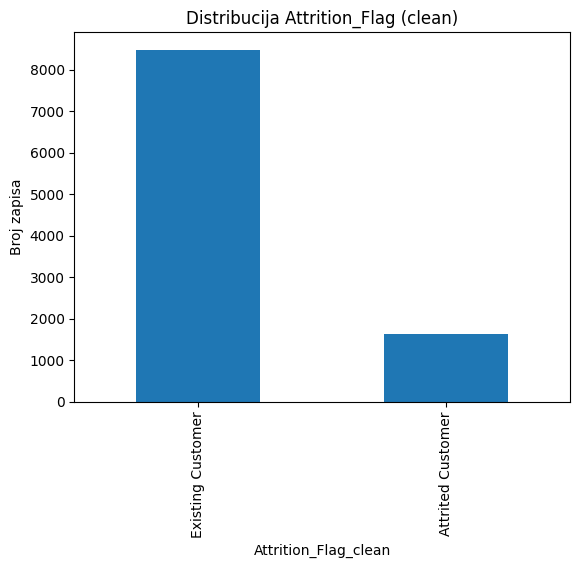

In [22]:
df['Attrition_Flag_clean'].value_counts().plot(kind='bar')
plt.title('Distribucija Attrition_Flag (clean)')
plt.ylabel('Broj zapisa')
plt.show()


**Kolona Customer_Age**

In [23]:
df["Customer_Age"].value_counts(dropna=False)


,count
Customer_Age,
49.0,359
44.0,340
43.0,336
46.0,328
45.0,327
...,...
957406,1
267439,1
755558,1


In [24]:
df["Customer_Age"].astype(str).unique()[:20]


array(['45.0', '49.0', 'nan', '-40.0', '44.0', '51.0', '32.0', '37.0',
       '48.0', '-42.0', '65.0X', '56.0', '35.0#', '57.0', '-48.0', '41.0',
       '61.0', '47.0', '141968', '47.0X'], dtype=object)

In [25]:
import pandas as pd
import numpy as np


df['Customer_Age_clean'] = df['Customer_Age'].astype(str).str.replace(r'[^\d.-]', '', regex=True)

df['Customer_Age_clean'] = pd.to_numeric(df['Customer_Age_clean'], errors='coerce')



df.loc[df['Customer_Age_clean'] < 18, 'Customer_Age_clean'] = np.nan
df.loc[df['Customer_Age_clean'] > 100, 'Customer_Age_clean'] = np.nan


median_age = df['Customer_Age_clean'].median()
df['Customer_Age_clean'] = df['Customer_Age_clean'].fillna(median_age)

# 5. Provjera
print("Deskriptivna statistika nakon čišćenja:")
print(df['Customer_Age_clean'].describe())

Deskriptivna statistika nakon čišćenja:
count    10127.000000
mean        46.253678
std          7.050153
min         26.000000
25%         43.000000
50%         46.000000
75%         50.000000
max         68.000000
Name: Customer_Age_clean, dtype: float64


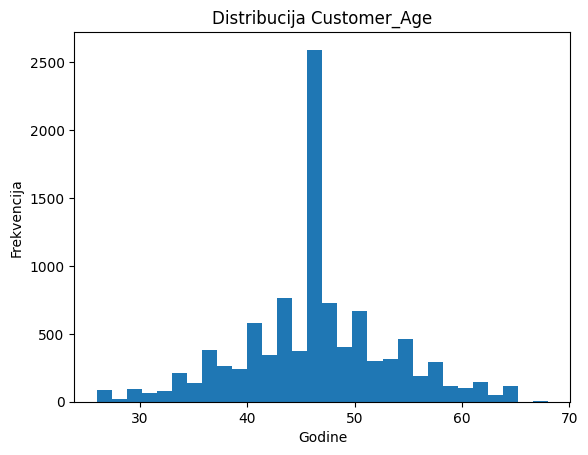

In [26]:
import matplotlib.pyplot as plt

plt.figure()
plt.hist(df['Customer_Age_clean'], bins=30)
plt.title('Distribucija Customer_Age')
plt.xlabel('Godine')
plt.ylabel('Frekvencija')
plt.show()


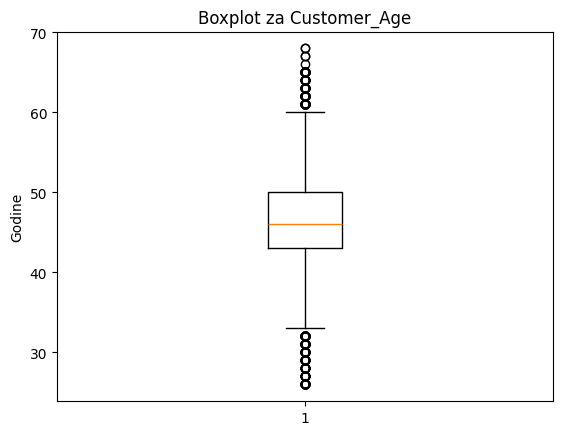

In [27]:
plt.figure()
plt.boxplot(df['Customer_Age_clean'])
plt.title('Boxplot za Customer_Age')
plt.ylabel('Godine')
plt.show()


**Kolona Gender**

In [28]:
df["Gender"].value_counts(dropna=False)


,count
Gender,
F,4648
M,4188
NaN,301
F_ERROR_VALUE,159
F_NOT_VALID,144
F_UNKNOWN,127
F_RANDOM_TEXT,123
M_NOT_VALID,120
M_RANDOM_TEXT,110


In [29]:
import pandas as pd
import numpy as np

def clean_gender(text):
    if pd.isna(text):
        return np.nan

    text = str(text).upper().strip()

    if text.startswith('F'):
        return 'F'
    elif text.startswith('M'):
        return 'M'
    else:
        return np.nan

df['Gender_clean'] = df['Gender'].apply(clean_gender)

most_freq_gender = df['Gender_clean'].mode()[0]
df['Gender_clean'] = df['Gender_clean'].fillna(most_freq_gender)

df['Gender_Encoded'] = df['Gender_clean'].map({'F': 0, 'M': 1})

print("Prije čišćenja:", df['Gender'].unique())
print("Poslije čišćenja:", df['Gender_clean'].unique())
print(df['Gender_clean'].value_counts())

Prije čišćenja: ['M' 'F' 'M_ERROR_VALUE' 'M_UNKNOWN' nan 'F_ERROR_VALUE' 'F_UNKNOWN'
 'M_RANDOM_TEXT' 'F_NOT_VALID' 'M_NOT_VALID' 'F_RANDOM_TEXT']
Poslije čišćenja: ['M' 'F']
Gender_clean
F    5502
M    4625
Name: count, dtype: int64


In [30]:
df['Gender_clean'].value_counts()


,count
Gender_clean,
F,5502
M,4625


In [31]:
pd.crosstab(
    df['Gender_clean'],
    df['Attrition_Flag_clean'],
    normalize='index'
)


Attrition_Flag_clean,Attrited Customer,Existing Customer
Gender_clean,,
F,0.173937,0.826063
M,0.148541,0.851459


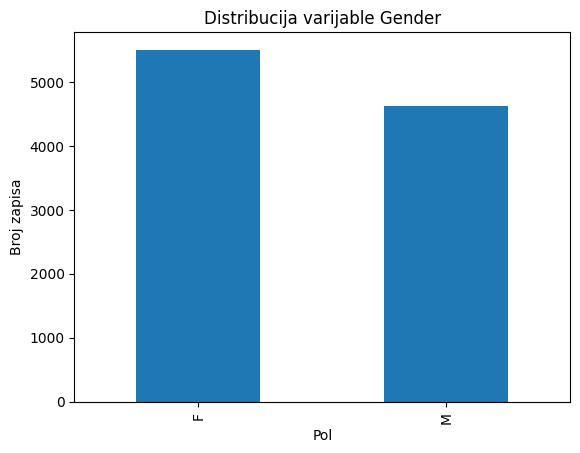

In [32]:
import matplotlib.pyplot as plt

df['Gender_clean'].value_counts().plot(kind='bar')
plt.title('Distribucija varijable Gender')
plt.xlabel('Pol')
plt.ylabel('Broj zapisa')
plt.show()


**Kolona Dependent_count**

In [33]:
df["Dependent_count"].value_counts(dropna=False).sort_index()


,count
Dependent_count,
-0.0,101
-1.0,181
-2.0,279
-3.0,272
-4.0,140
...,...
997629,1
998262,1
998453,1


In [34]:
df["Dependent_count"].value_counts(dropna=False).sort_index()


,count
Dependent_count,
-0.0,101
-1.0,181
-2.0,279
-3.0,272
-4.0,140
...,...
997629,1
998262,1
998453,1


In [35]:
df["Dependent_count"].astype(str).unique()[:100]


array(['3.0', '5.0', '4.0', '-2.0', '0.0', '564797', '2.0*', '1.0X',
       '1.0', '860634', '281625', 'nan', '2.0', '2.0#', '3.0#', '251772',
       '595818', '-1.0', '1.0*', '-5.0', '672268', '452048', '2.0X',
       '-3.0', '448223', '3.0*', '607959', '542370', '873873', '1.0#',
       '670867', '393448', '813168', '672135', '4.0#', '681798', '355025',
       '-4.0', '-0.0', '267991', '5.0X', '876601', '407512', '0.0*',
       '699185', '339688', '323027', '737735', '871186', '166887',
       '397817', '4.0*', '537906', '503459', '4.0X', '257325', '395770',
       '195101', '731938', '383918', '799872', '825549', '278160',
       '137239', '500352', '402618', '463856', '930119', '711898',
       '826977', '261750', '747653', '3.0X', '798941', '334047', '860833',
       '217049', '281832', '990297', '622263', '914651', '0.0X', '841781',
       '800324', '434302', '770750', '745589', '115995', '172300',
       '797382', '104547', '865722', '137800', '441201', '783228',
       '575418'

In [36]:
import pandas as pd
import numpy as np


df['Dependent_count_clean'] = df['Dependent_count'].astype(str).str.replace(r'[^\d.-]', '', regex=True)

df['Dependent_count_clean'] = pd.to_numeric(df['Dependent_count_clean'], errors='coerce')


df.loc[df['Dependent_count_clean'] < 0, 'Dependent_count_clean'] = np.nan
df.loc[df['Dependent_count_clean'] > 10, 'Dependent_count_clean'] = np.nan


median_dep = df['Dependent_count_clean'].median()
df['Dependent_count_clean'] = df['Dependent_count_clean'].fillna(median_dep)

print("Deskriptivna statistika nakon čišćenja:")
print(df['Dependent_count_clean'].describe())
print(df['Dependent_count_clean'].value_counts().sort_index())

Deskriptivna statistika nakon čišćenja:
count    10127.000000
mean         2.252395
std          1.171324
min          0.000000
25%          2.000000
50%          2.000000
75%          3.000000
max          5.000000
Name: Dependent_count_clean, dtype: float64
Dependent_count_clean
0.0     787
1.0    1424
2.0    4248
3.0    2102
4.0    1246
5.0     320
Name: count, dtype: int64


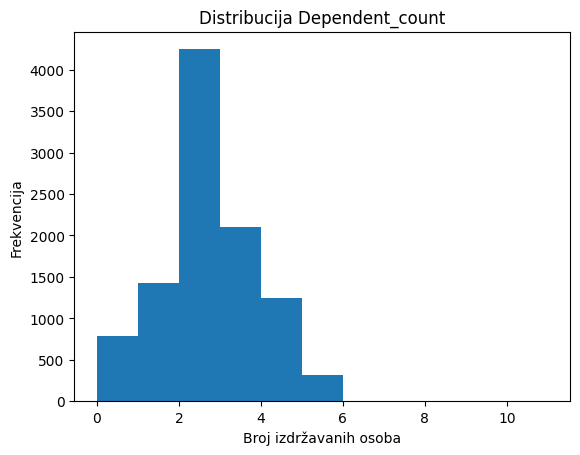

In [37]:
import matplotlib.pyplot as plt

plt.figure()
plt.hist(df['Dependent_count_clean'], bins=range(0, 12))
plt.title('Distribucija Dependent_count')
plt.xlabel('Broj izdržavanih osoba')
plt.ylabel('Frekvencija')
plt.show()

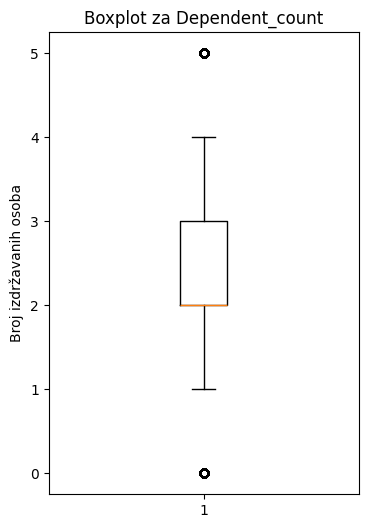

In [38]:
plt.figure(figsize=(4,6))
plt.boxplot(df['Dependent_count_clean'], vert=True)
plt.title('Boxplot za Dependent_count')
plt.ylabel('Broj izdržavanih osoba')
plt.show()


**Kolona Education_Level**

In [39]:
df["Education_Level"].value_counts(dropna=False)


,count
Education_Level,
Graduate,2445
High School,1536
Unknown,1178
Uneducated,1150
College,793
...,...
HcgiS hhool,1
Pastdatro-uGe,1
Udtueaecnd,1


In [40]:
df["Education_Level"].value_counts(dropna=False).to_string()


'Education_Level\nGraduate                     2445\nHigh School                  1536\nUnknown                      1178\nUneducated                   1150\nCollege                       793\nPost-Graduate                 399\nDoctorate                     360\nNaN                           296\nGraduate_ERROR_VALUE           90\nGraduate_RANDOM_TEXT           83\nGraduate_NOT_VALID             81\nGraduate_UNKNOWN               69\nHigh School_NOT_VALID          59\nHigh School_UNKNOWN            56\nHigh School_ERROR_VALUE        47\nUnknown_ERROR_VALUE            47\nUneducated_UNKNOWN             45\nUnknown_RANDOM_TEXT            45\nHigh School_RANDOM_TEXT        42\nUneducated_ERROR_VALUE         41\nUnknown_NOT_VALID              38\nUneducated_RANDOM_TEXT         36\nUneducated_NOT_VALID           31\nUnknown_UNKNOWN                31\nCollege_NOT_VALID              21\nCollege_ERROR_VALUE            21\nCollege_RANDOM_TEXT            20\nCollege_UNKNOWN                18\nPo

In [41]:
import pandas as pd
from difflib import get_close_matches


valid_edu_levels = [
    'Post-Graduate',
    'High School',
    'Graduate',
    'Uneducated',
    'College',
    'Doctorate',
    'Unknown'
]

def clean_education_level(text):
    if pd.isna(text):
        return "Unknown"

    text = str(text).strip()


    for level in valid_edu_levels:
        if level in text:
            return level


    matches = get_close_matches(text, valid_edu_levels, n=1, cutoff=0.5)

    if matches:
        return matches[0]

    return "Unknown"

df['Education_Level_clean'] = df['Education_Level'].apply(clean_education_level)

print("Broj kategorija prije:", df['Education_Level'].nunique())
print("Broj kategorija poslije:", df['Education_Level_clean'].nunique())
print("\nRezultat:")
print(df['Education_Level_clean'].value_counts())




Broj kategorija prije: 767
Broj kategorija poslije: 7

Rezultat:
Education_Level_clean
Graduate         3041
Unknown          1915
High School      1892
Uneducated       1384
College           980
Post-Graduate     476
Doctorate         439
Name: count, dtype: int64


In [42]:
df['Education_Level_clean'].value_counts(normalize=True) * 100


,proportion
Education_Level_clean,
Graduate,30.028636
Unknown,18.909845
High School,18.682729
Uneducated,13.666436
College,9.677101
Post-Graduate,4.700306
Doctorate,4.334946


In [43]:
pd.crosstab(
    df['Education_Level_clean'],
    df['Attrition_Flag_clean'],
    normalize='index'
)


Attrition_Flag_clean,Attrited Customer,Existing Customer
Education_Level_clean,,
College,0.152041,0.847959
Doctorate,0.220957,0.779043
Graduate,0.158500,0.841500
High School,0.153805,0.846195
Post-Graduate,0.186975,0.813025
Uneducated,0.161127,0.838873
Unknown,0.163446,0.836554


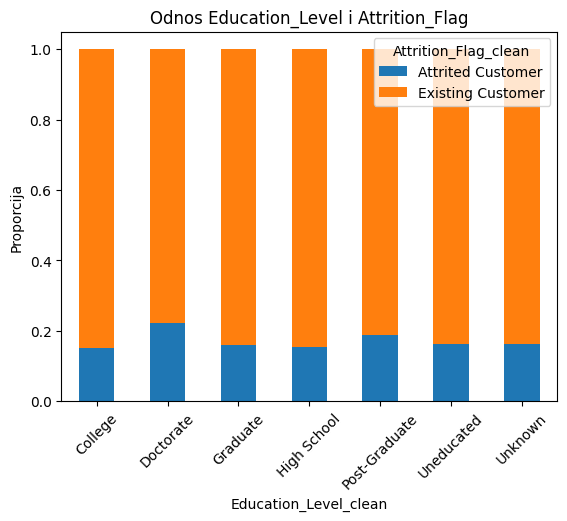

In [44]:
pd.crosstab(
    df['Education_Level_clean'],
    df['Attrition_Flag_clean'],
    normalize='index'
).plot(kind='bar', stacked=True)

plt.title('Odnos Education_Level i Attrition_Flag')
plt.ylabel('Proporcija')
plt.xticks(rotation=45)
plt.show()


**Kolona Marital_Status**

In [45]:
df["Marital_Status"].value_counts(dropna=False)


,count
Marital_Status,
Married,3669
Single,3088
Divorced,586
Unknown,584
NaN,290
...,...
Dirocevd,1
Uwnonkn,1
Dercivod,1


In [46]:
df["Marital_Status"].value_counts(dropna=False).to_string()


'Marital_Status\nMarried                 3669\nSingle                  3088\nDivorced                 586\nUnknown                  584\nNaN                      290\nSingle_RANDOM_TEXT       120\nSingle_NOT_VALID         114\nMarried_NOT_VALID        113\nMarried_ERROR_VALUE      113\nMarried_RANDOM_TEXT       91\nSingle_ERROR_VALUE        88\nMarried_UNKNOWN           85\nSingle_UNKNOWN            84\nSngile                    23\nSgilne                    22\nUnknown_RANDOM_TEXT       20\nDivorced_ERROR_VALUE      20\nSnigle                    20\nDivorced_RANDOM_TEXT      20\nSginle                    19\nSlngie                    18\nUnknown_NOT_VALID         18\nSlgnie                    18\nSgnlie                    17\nSilnge                    16\nSnilge                    16\nUnknown_ERROR_VALUE       16\nSgnile                    16\nSlnige                    16\nSinlge                    15\nDivorced_UNKNOWN          15\nSnlige                    15\nUnknown_UNKNOWN        

In [47]:
df["Marital_Status"].astype(str).unique()


array(['Married', 'Single', 'Unknown', 'Marreid', 'Uoknnwn', 'Slngie',
       'nan', 'Married_NOT_VALID', 'Divorced', 'Maerrid', 'Mireard',
       'Married_ERROR_VALUE', 'Divorced_ERROR_VALUE', 'Single_UNKNOWN',
       'Mrieard', 'Divorced_NOT_VALID', 'Dvicored', 'Single_ERROR_VALUE',
       'Unknown_ERROR_VALUE', 'Uownnkn', 'Mrreiad', 'Sgnile', 'Mreaird',
       'Married_RANDOM_TEXT', 'Mrareid', 'Maerird', 'Miearrd',
       'Single_NOT_VALID', 'Mrriead', 'Mreriad', 'Mairred', 'Sinlge',
       'Silnge', 'Single_RANDOM_TEXT', 'Dvrioecd', 'Mrierad', 'Mierrad',
       'Sgnlie', 'Sgilne', 'Merarid', 'Mraerid', 'Mirerad',
       'Married_UNKNOWN', 'Maeirrd', 'Mriread', 'Marerid', 'Ukwonnn',
       'Unknown_UNKNOWN', 'Miraerd', 'Mearrid', 'Dvecirod', 'Mriared',
       'Slgine', 'Sligne', 'Dveriocd', 'Mrearid', 'Meriard', 'Sglnie',
       'Siglne', 'Dirovecd', 'Unknown_NOT_VALID', 'Miaerrd', 'Marierd',
       'Divorced_RANDOM_TEXT', 'Merriad', 'Diecorvd',
       'Unknown_RANDOM_TEXT', 'Mraier

In [48]:
import pandas as pd
from difflib import get_close_matches

valid_status = ['Married', 'Single', 'Divorced', 'Unknown']

def clean_marital_status(text):
    if pd.isna(text):
        return "Unknown"

    text = str(text).strip()

    for status in valid_status:
        if status in text:
            return status

    matches = get_close_matches(text, valid_status, n=1, cutoff=0.5)

    if matches:
        return matches[0]

    return "Unknown"

df['Marital_Status_clean'] = df['Marital_Status'].apply(clean_marital_status)

print("Broj kategorija prije:", df['Marital_Status'].nunique())
print("Broj kategorija poslije:", df['Marital_Status_clean'].nunique())
print(df['Marital_Status_clean'].value_counts())

Broj kategorija prije: 212
Broj kategorija poslije: 4
Marital_Status_clean
Married     4522
Single      3847
Unknown     1036
Divorced     722
Name: count, dtype: int64


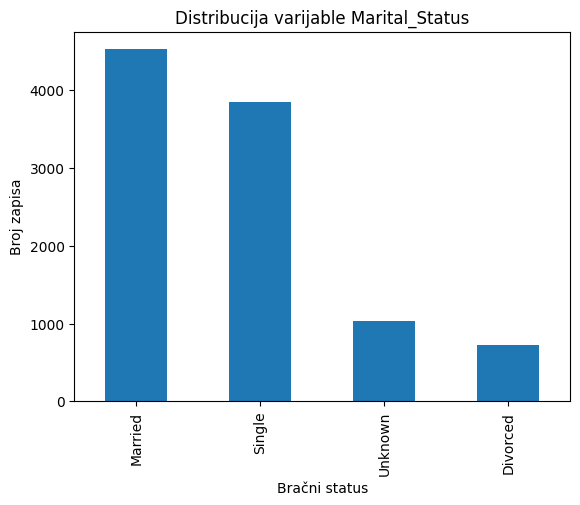

In [49]:
import matplotlib.pyplot as plt

df['Marital_Status_clean'].value_counts().plot(kind='bar')
plt.title('Distribucija varijable Marital_Status')
plt.xlabel('Bračni status')
plt.ylabel('Broj zapisa')
plt.show()


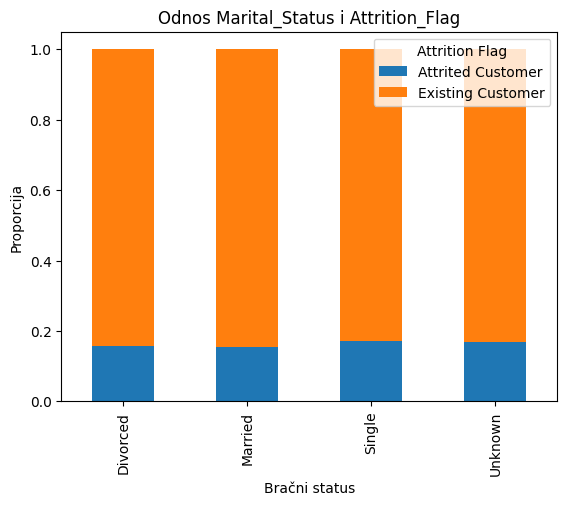

In [50]:
pd.crosstab(
    df['Marital_Status_clean'],
    df['Attrition_Flag_clean'],
    normalize='index'
).plot(kind='bar', stacked=True)

plt.title('Odnos Marital_Status i Attrition_Flag')
plt.xlabel('Bračni status')
plt.ylabel('Proporcija')
plt.legend(title='Attrition Flag')
plt.show()


**Kolona Income_Category**

In [51]:
df["Income_Category"].value_counts(dropna=False)

,count
Income_Category,
Less than $40K,2423
$40K - $60K,1221
$80K - $120K,1026
$60K - $80K,946
Unknown,870
...,...
$ $0-K086 K,1
Ls$4nh 0se taK,1
Uownnkn,1


In [52]:
df["Income_Category"].value_counts(dropna=False).to_string()


'Income_Category\nLess than $40K                2423\n$40K - $60K                   1221\n$80K - $120K                  1026\n$60K - $80K                    946\nUnknown                        870\n$120K +                        486\nLess than KM40K                353\nNaN                            307\nKM40K - KM60K                  188\nKM80K - KM120K                 154\nKM60K - KM80K                  116\nLess than $40K_ERROR_VALUE      92\nLess than $40K_UNKNOWN          92\nLess than $40K_RANDOM_TEXT      81\nLess than $40K_NOT_VALID        80\nKM120K +                        67\n$80K - $120K_RANDOM_TEXT        50\n$80K - $120K_UNKNOWN            49\n$40K - $60K_ERROR_VALUE         48\n$60K - $80K_ERROR_VALUE         45\n$40K - $60K_NOT_VALID           42\n$60K - $80K_NOT_VALID           42\n$40K - $60K_RANDOM_TEXT         40\nUnknown_RANDOM_TEXT             36\n$80K - $120K_ERROR_VALUE        35\n$80K - $120K_NOT_VALID          34\n$60K - $80K_RANDOM_TEXT         33\nUnknown_ER

In [53]:
import pandas as pd

def clean_income_category(text):
    if pd.isna(text):
        return "Unknown"

    text = str(text).lower()

    if not any(char.isdigit() for char in text):
        return "Unknown"


    if '8' in text and '1' in text and '2' in text:
        return '$80K - $120K'

    elif '6' in text and '8' in text:
        return '$60K - $80K'

    elif '4' in text and '6' in text:
        return '$40K - $60K'

    elif '1' in text and '2' in text:
        return '$120K +'

    elif '4' in text:
        return 'Less than $40K'

    else:
        return "Unknown"

df['Income_Category_clean'] = df['Income_Category'].apply(clean_income_category)

print("Broj kategorija prije:", df['Income_Category'].nunique())
print("Broj kategorija poslije:", df['Income_Category_clean'].nunique())
print("\nRezultat:")
print(df['Income_Category_clean'].value_counts())

income_map = {
    'Unknown': 0,
    'Less than $40K': 1,
    '$40K - $60K': 2,
    '$60K - $80K': 3,
    '$80K - $120K': 4,
    '$120K +': 5
}


Broj kategorija prije: 930
Broj kategorija poslije: 6

Rezultat:
Income_Category_clean
Less than $40K    3438
$40K - $60K       1737
$80K - $120K      1499
Unknown           1391
$60K - $80K       1357
$120K +            705
Name: count, dtype: int64


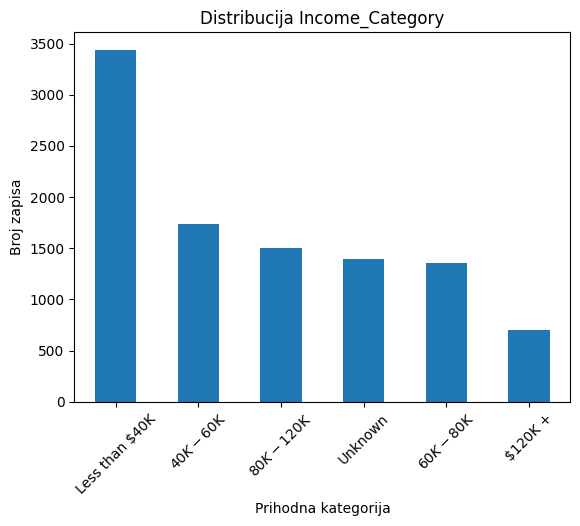

In [54]:
import matplotlib.pyplot as plt

df['Income_Category_clean'].value_counts().plot(kind='bar')
plt.title('Distribucija Income_Category')
plt.xlabel('Prihodna kategorija')
plt.ylabel('Broj zapisa')
plt.xticks(rotation=45)
plt.show()


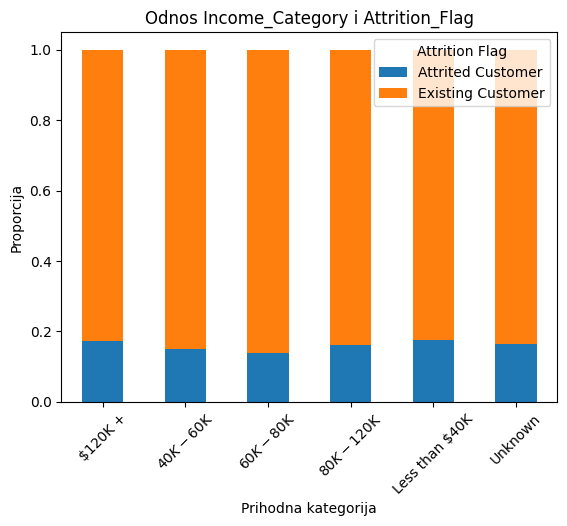

In [55]:
pd.crosstab(
    df['Income_Category_clean'],
    df['Attrition_Flag_clean'],
    normalize='index'
).plot(kind='bar', stacked=True)

plt.title('Odnos Income_Category i Attrition_Flag')
plt.xlabel('Prihodna kategorija')
plt.ylabel('Proporcija')
plt.legend(title='Attrition Flag')
plt.xticks(rotation=45)
plt.show()


**Kolona Card_Category**

In [56]:
df["Card_Category"].value_counts(dropna=False)


,count
Card_Category,
Blue,7791
Bule,465
Silver,448
NaN,301
Blue_ERROR_VALUE,236
Blue_RANDOM_TEXT,227
Blue_UNKNOWN,221
Blue_NOT_VALID,214
Gold,93


In [57]:
df["Card_Category"].astype(str).unique()


array(['Bule', 'Blue', 'Gold', 'Silver', 'Blue_ERROR_VALUE',
       'Blue_RANDOM_TEXT', 'Blue_NOT_VALID', 'Glod', 'nan',
       'Blue_UNKNOWN', 'Sveilr', 'Silver_ERROR_VALUE',
       'Silver_RANDOM_TEXT', 'Platinum', 'Gold_NOT_VALID', 'Slveir',
       'Sivler', 'Silver_NOT_VALID', 'Sviler', 'Silver_UNKNOWN', 'Slievr',
       'Gold_UNKNOWN', 'Svlier', 'Seilvr', 'Slvier', 'Sevlir', 'Sleivr',
       'Gold_RANDOM_TEXT', 'Silevr', 'Gold_ERROR_VALUE', 'Svielr',
       'Seivlr', 'Sliver', 'Platinum_NOT_VALID', 'Selvir', 'Sevilr',
       'Sielvr'], dtype=object)

In [58]:
import pandas as pd
from difflib import get_close_matches

valid_cards = ['Blue', 'Silver', 'Gold', 'Platinum']

def clean_card_category(text):

    if pd.isna(text):
        return "Unknown"

    text_lower = str(text).lower()



    if 'platinum' in text_lower:
        return 'Platinum'
    if 'silver' in text_lower:
        return 'Silver'
    if 'gold' in text_lower:
        return 'Gold'
    if 'blue' in text_lower or 'bule' in text_lower:
        return 'Blue'


    matches = get_close_matches(text_lower.title(), valid_cards, n=1, cutoff=0.6)

    if matches:
        return matches[0]

    return "Unknown"

df['Card_Category_clean'] = df['Card_Category'].apply(clean_card_category)

print(df['Card_Category_clean'].value_counts())

Card_Category_clean
Blue        9154
Silver       538
Unknown      303
Gold         113
Platinum      19
Name: count, dtype: int64


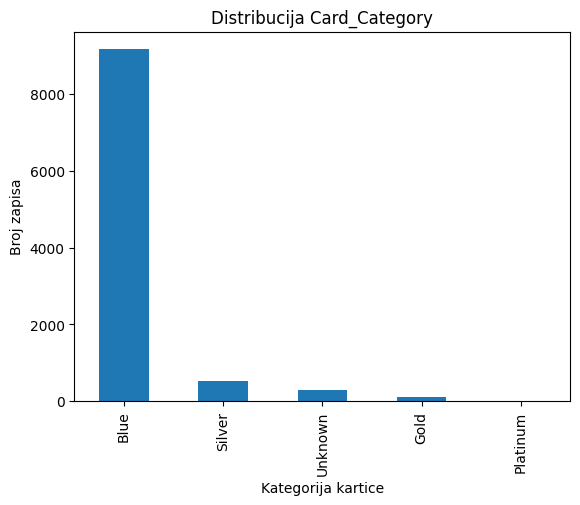

In [59]:
import matplotlib.pyplot as plt

df['Card_Category_clean'].value_counts().plot(kind='bar')
plt.title('Distribucija Card_Category')
plt.xlabel('Kategorija kartice')
plt.ylabel('Broj zapisa')
plt.show()


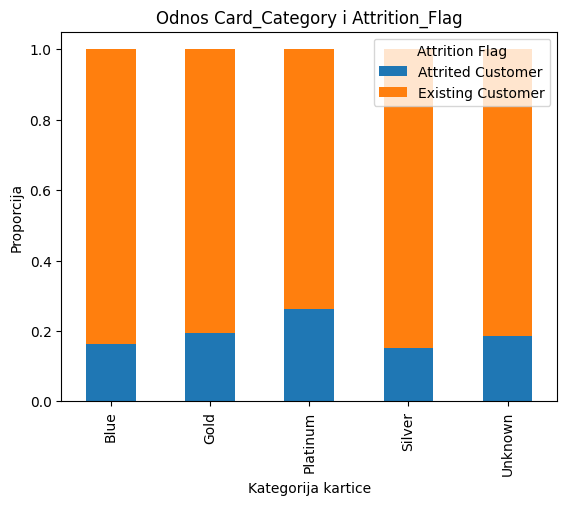

In [60]:
pd.crosstab(
    df['Card_Category_clean'],
    df['Attrition_Flag_clean'],
    normalize='index'
).plot(kind='bar', stacked=True)

plt.title('Odnos Card_Category i Attrition_Flag')
plt.xlabel('Kategorija kartice')
plt.ylabel('Proporcija')
plt.legend(title='Attrition Flag')
plt.show()


**Kolona Months_on_book**

In [61]:
df["Months_on_book"].value_counts(dropna=False)


,count
Months_on_book,
36.0,1677
NaN,313
34.0,242
37.0,238
-36.0,238
...,...
958598,1
890422,1
410120,1


In [62]:
df["Months_on_book"].value_counts(dropna=False).sort_index()


,count
Months_on_book,
-13.0,6
-14.0,1
-15.0,3
-16.0,2
-17.0,6
...,...
998210,1
998811,1
999512,1


In [63]:
print(df["Months_on_book"].value_counts(dropna=False).sort_index().to_string())


Months_on_book
-13.0        6
-14.0        1
-15.0        3
-16.0        2
-17.0        6
-18.0        9
-19.0        9
-20.0        7
-21.0        6
-22.0        5
-23.0       14
-24.0       14
-25.0       18
-26.0       16
-27.0       17
-28.0       32
-29.0       34
-30.0       22
-31.0       34
-32.0       26
-33.0       26
-34.0       18
-35.0       37
-36.0      238
-37.0       39
-38.0       32
-39.0       31
-40.0       28
-41.0       28
-42.0       23
-43.0       33
-44.0       27
-45.0       24
-46.0       22
-47.0       19
-48.0       12
-49.0       11
-50.0       12
-51.0        7
-52.0        5
-53.0        6
-54.0        5
-55.0        4
-56.0       10
100174       1
100802       1
101699       1
101921       1
102405       1
104364       1
104411       1
104463       1
104739       1
106268       1
106289       1
106456       1
107989       1
108513       1
108542       1
109204       1
109239       1
110870       1
110921       1
110951       1
111695       1
113264    

In [64]:
df["Months_on_book"].astype(str).unique()[:20]


array(['39.0', '44.0', '-36.0', '34.0#', '838122', '36.0', '46.0*',
       '27.0', '36.0#', '291220', '54.0', '30.0', '48.0', '37.0', '34.0',
       '671903', '42.0', '49.0', '804046', '28.0'], dtype=object)

In [65]:
import pandas as pd
import numpy as np


df['Months_on_book_clean'] = df['Months_on_book'].astype(str).str.replace(r'[^\d.-]', '', regex=True)

df['Months_on_book_clean'] = pd.to_numeric(df['Months_on_book_clean'], errors='coerce')



df.loc[df['Months_on_book_clean'] < 0, 'Months_on_book_clean'] = np.nan


df.loc[df['Months_on_book_clean'] > 100, 'Months_on_book_clean'] = np.nan


median_val = df['Months_on_book_clean'].median()
df['Months_on_book_clean'] = df['Months_on_book_clean'].fillna(median_val)

print("Deskriptivna statistika nakon čišćenja:")
print(df['Months_on_book_clean'].describe())

Deskriptivna statistika nakon čišćenja:
count    10127.000000
mean        35.941641
std          7.019558
min         13.000000
25%         34.000000
50%         36.000000
75%         38.000000
max         56.000000
Name: Months_on_book_clean, dtype: float64


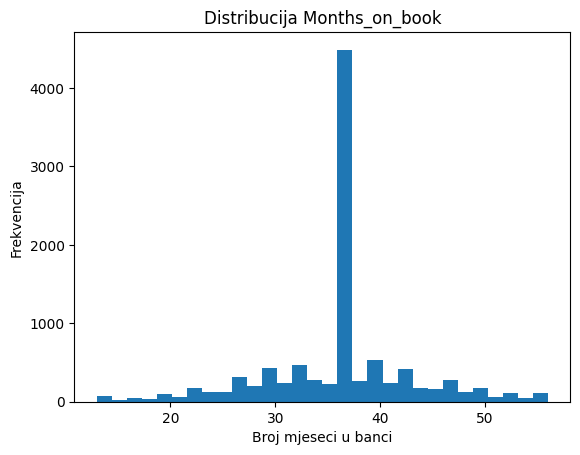

In [66]:
import matplotlib.pyplot as plt

plt.figure()
plt.hist(df['Months_on_book_clean'], bins=30)
plt.title('Distribucija Months_on_book')
plt.xlabel('Broj mjeseci u banci')
plt.ylabel('Frekvencija')
plt.show()


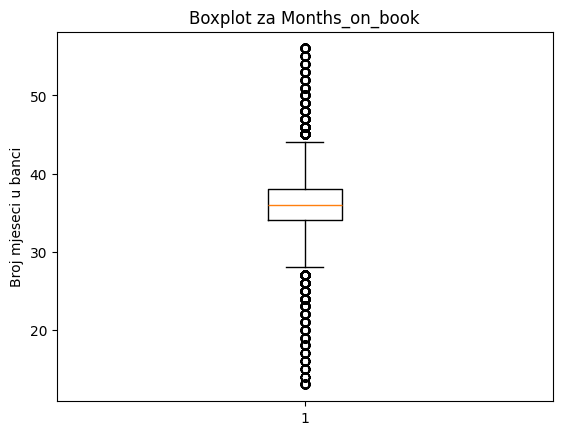

In [67]:
plt.figure()
plt.boxplot(df['Months_on_book_clean'])
plt.title('Boxplot za Months_on_book')
plt.ylabel('Broj mjeseci u banci')
plt.show()


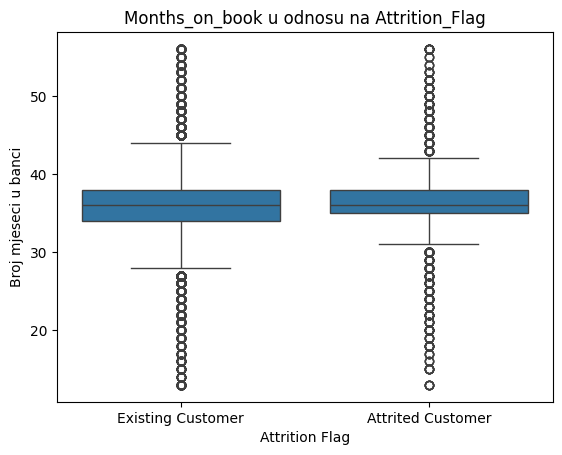

In [68]:
import seaborn as sns

plt.figure()
sns.boxplot(
    x=df['Attrition_Flag_clean'],
    y=df['Months_on_book_clean']
)
plt.title('Months_on_book u odnosu na Attrition_Flag')
plt.xlabel('Attrition Flag')
plt.ylabel('Broj mjeseci u banci')
plt.show()


**Kolona Total_Relationship_Count**

In [69]:
df["Total_Relationship_Count"].value_counts(dropna=False).sort_index()


,count
Total_Relationship_Count,
-1.0,78
-2.0,121
-3.0,233
-4.0,186
-5.0,176
...,...
994822,1
995634,1
996901,1


In [70]:
print(df["Total_Relationship_Count"].value_counts(dropna=False).sort_index().to_string())


Total_Relationship_Count
-1.0          78
-2.0         121
-3.0         233
-4.0         186
-5.0         176
-6.0         172
1.0          634
1.0#          35
1.0*          22
1.0X          26
100197         1
100350         1
101523         1
101747         1
101779         1
102308         1
104083         1
104269         1
106067         1
109052         1
109968         1
111986         1
112486         1
115296         1
117428         1
117668         1
117877         1
118368         1
118968         1
119961         1
124492         1
126975         1
129237         1
130531         1
131613         1
131820         1
132048         1
132055         1
132058         1
132564         1
133077         1
133107         1
134967         1
135315         1
135414         1
138106         1
139086         1
139596         1
139628         1
140463         1
140813         1
140926         1
143126         1
143387         1
143627         1
144826         1
147864         1
149031

In [71]:
df["Total_Relationship_Count"].astype(str).unique()[:20]


array(['851878', '6.0', '-4.0', '3.0', '5.0', '6.0#', '2.0', '662174',
       '5.0X', '4.0', '878978', '-3.0', '-5.0', '500786', '798568',
       '683579', '943163', '1.0', '821362', 'nan'], dtype=object)

In [72]:
import pandas as pd
import numpy as np

df['Total_Relationship_Count_clean'] = df['Total_Relationship_Count'].astype(str).str.replace(r'[^\d.-]', '', regex=True)

df['Total_Relationship_Count_clean'] = pd.to_numeric(df['Total_Relationship_Count_clean'], errors='coerce')


df.loc[df['Total_Relationship_Count_clean'] < 0, 'Total_Relationship_Count_clean'] = np.nan
df.loc[df['Total_Relationship_Count_clean'] > 10, 'Total_Relationship_Count_clean'] = np.nan

median_rel = df['Total_Relationship_Count_clean'].median()
df['Total_Relationship_Count_clean'] = df['Total_Relationship_Count_clean'].fillna(median_rel)

print("Deskriptivna statistika poslije čišćenja:")
print(df['Total_Relationship_Count_clean'].describe())
print("\nValue counts:")
print(df['Total_Relationship_Count_clean'].value_counts().sort_index())

Deskriptivna statistika poslije čišćenja:
count    10127.000000
mean         3.858793
std          1.376924
min          1.000000
25%          3.000000
50%          4.000000
75%          5.000000
max          6.000000
Name: Total_Relationship_Count_clean, dtype: float64

Value counts:
Total_Relationship_Count_clean
1.0     717
2.0     955
3.0    1781
4.0    3729
5.0    1478
6.0    1467
Name: count, dtype: int64


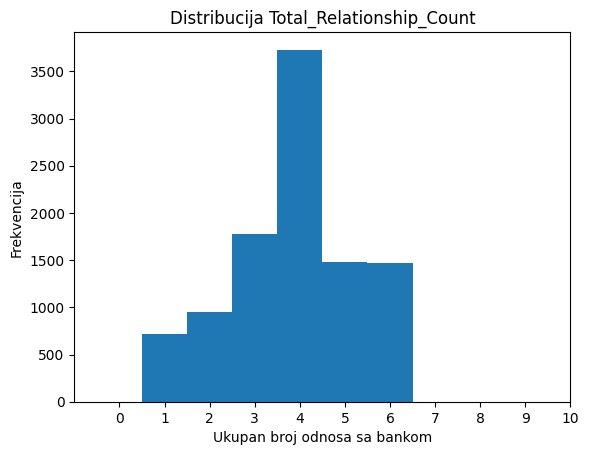

In [73]:
import matplotlib.pyplot as plt

plt.figure()
plt.hist(df['Total_Relationship_Count_clean'], bins=range(0, 11), align='left')
plt.title('Distribucija Total_Relationship_Count')
plt.xlabel('Ukupan broj odnosa sa bankom')
plt.ylabel('Frekvencija')
plt.xticks(range(0, 11))
plt.show()


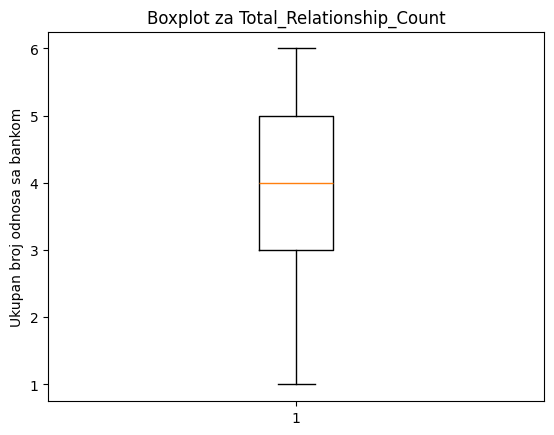

In [74]:
plt.figure()
plt.boxplot(df['Total_Relationship_Count_clean'])
plt.title('Boxplot za Total_Relationship_Count')
plt.ylabel('Ukupan broj odnosa sa bankom')
plt.show()


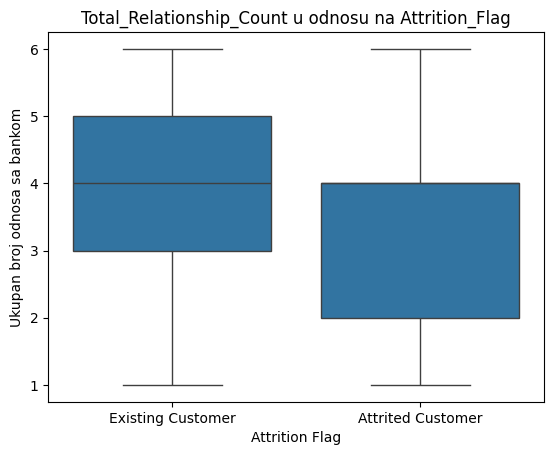

In [75]:
import seaborn as sns

plt.figure()
sns.boxplot(
    x=df['Attrition_Flag_clean'],
    y=df['Total_Relationship_Count_clean']
)
plt.title('Total_Relationship_Count u odnosu na Attrition_Flag')
plt.xlabel('Attrition Flag')
plt.ylabel('Ukupan broj odnosa sa bankom')
plt.show()


**Kolona Months_Inactive_12_mon**

In [76]:
df["Months_Inactive_12_mon"].value_counts(dropna=False).sort_index()


,count
Months_Inactive_12_mon,
-0.0,3
-1.0,221
-2.0,298
-3.0,390
-4.0,30
...,...
996251,1
997055,1
998740,1


In [77]:
df["Months_Inactive_12_mon"].apply(type).value_counts()


,count
Months_Inactive_12_mon,
<class 'str'>,9828
<class 'float'>,299


In [78]:
import pandas as pd
import numpy as np

df['Months_Inactive_clean'] = df['Months_Inactive_12_mon'].astype(str).str.replace(r'[^\d.-]', '', regex=True)

df['Months_Inactive_clean'] = pd.to_numeric(df['Months_Inactive_clean'], errors='coerce')

df.loc[df['Months_Inactive_clean'] < 0, 'Months_Inactive_clean'] = np.nan
df.loc[df['Months_Inactive_clean'] > 12, 'Months_Inactive_clean'] = np.nan

median_val = df['Months_Inactive_clean'].median()
df['Months_Inactive_clean'] = df['Months_Inactive_clean'].fillna(median_val)

print("Opseg vrijednosti nakon čišćenja:")
print(f"Min: {df['Months_Inactive_clean'].min()}, Max: {df['Months_Inactive_clean'].max()}")
print(df['Months_Inactive_clean'].value_counts().sort_index())

Opseg vrijednosti nakon čišćenja:
Min: 0.0, Max: 6.0
Months_Inactive_clean
0.0      25
1.0    1708
2.0    4796
3.0    3018
4.0     347
5.0     134
6.0      99
Name: count, dtype: int64


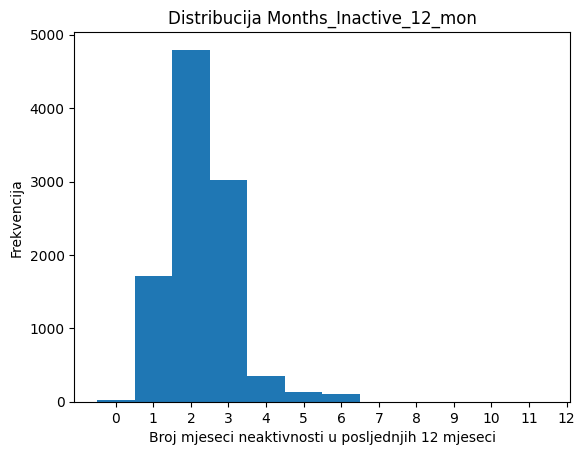

In [79]:
import matplotlib.pyplot as plt

plt.figure()
plt.hist(df['Months_Inactive_clean'], bins=range(0, 13), align='left')
plt.title('Distribucija Months_Inactive_12_mon')
plt.xlabel('Broj mjeseci neaktivnosti u posljednjih 12 mjeseci')
plt.ylabel('Frekvencija')
plt.xticks(range(0, 13))
plt.show()


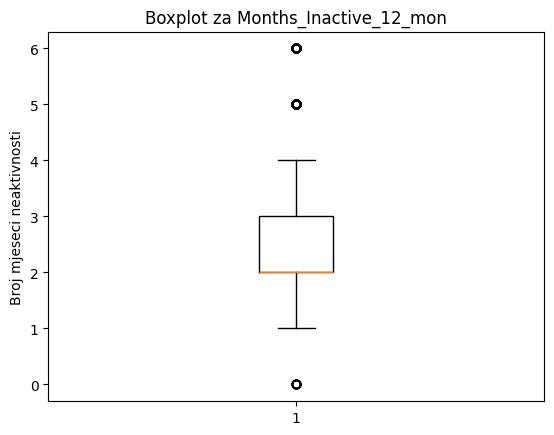

In [80]:
plt.figure()
plt.boxplot(df['Months_Inactive_clean'])
plt.title('Boxplot za Months_Inactive_12_mon')
plt.ylabel('Broj mjeseci neaktivnosti')
plt.show()


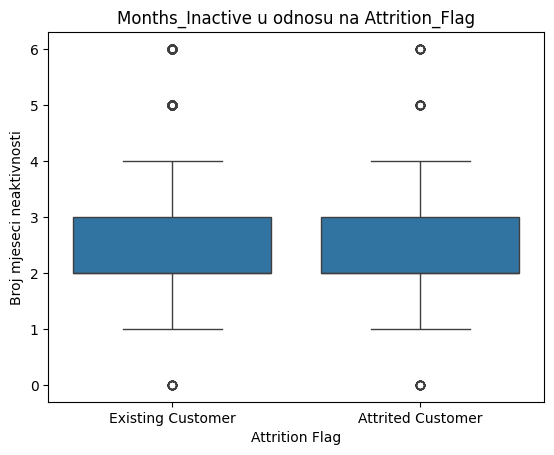

In [81]:
import seaborn as sns

plt.figure()
sns.boxplot(
    x=df['Attrition_Flag_clean'],
    y=df['Months_Inactive_clean']
)
plt.title('Months_Inactive u odnosu na Attrition_Flag')
plt.xlabel('Attrition Flag')
plt.ylabel('Broj mjeseci neaktivnosti')
plt.show()


**Kolona Contacts_Count_12_mon**

In [82]:
df["Contacts_Count_12_mon"].apply(type).value_counts()


,count
Contacts_Count_12_mon,
<class 'str'>,9866
<class 'float'>,261


In [83]:
df["Contacts_Count_12_mon"].value_counts(dropna=False).sort_index()


,count
Contacts_Count_12_mon,
-0.0,30
-1.0,137
-2.0,318
-3.0,348
-4.0,137
...,...
995811,1
996287,1
998401,1


In [84]:
import pandas as pd
import numpy as np


df['Contacts_Count_clean'] = df['Contacts_Count_12_mon'].astype(str).str.replace(r'[^\d.-]', '', regex=True)

df['Contacts_Count_clean'] = pd.to_numeric(df['Contacts_Count_clean'], errors='coerce')



df.loc[df['Contacts_Count_clean'] < 0, 'Contacts_Count_clean'] = np.nan
df.loc[df['Contacts_Count_clean'] > 20, 'Contacts_Count_clean'] = np.nan


median_contacts = df['Contacts_Count_clean'].median()
df['Contacts_Count_clean'] = df['Contacts_Count_clean'].fillna(median_contacts)

print("Deskriptivna statistika nakon čišćenja:")
print(df['Contacts_Count_clean'].describe())
print(df['Contacts_Count_clean'].value_counts().sort_index())

Deskriptivna statistika nakon čišćenja:
count    10127.000000
mean         2.351832
std          1.009995
min          0.000000
25%          2.000000
50%          2.000000
75%          3.000000
max          6.000000
Name: Contacts_Count_clean, dtype: float64
Contacts_Count_clean
0.0     341
1.0    1172
2.0    4726
3.0    2599
4.0    1095
5.0     148
6.0      46
Name: count, dtype: int64


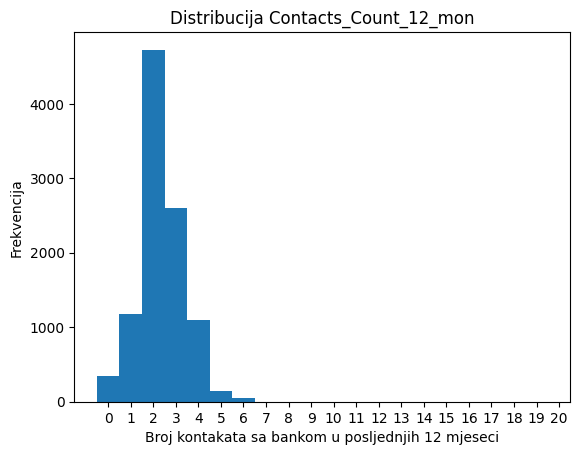

In [85]:
import matplotlib.pyplot as plt

plt.figure()
plt.hist(df['Contacts_Count_clean'], bins=range(0, 21), align='left')
plt.title('Distribucija Contacts_Count_12_mon')
plt.xlabel('Broj kontakata sa bankom u posljednjih 12 mjeseci')
plt.ylabel('Frekvencija')
plt.xticks(range(0, 21))
plt.show()


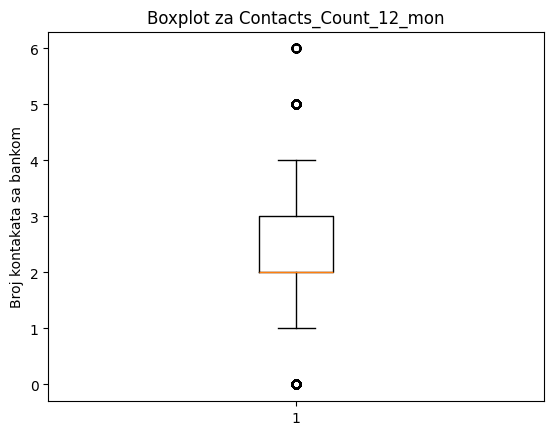

In [86]:
plt.figure()
plt.boxplot(df['Contacts_Count_clean'])
plt.title('Boxplot za Contacts_Count_12_mon')
plt.ylabel('Broj kontakata sa bankom')
plt.show()


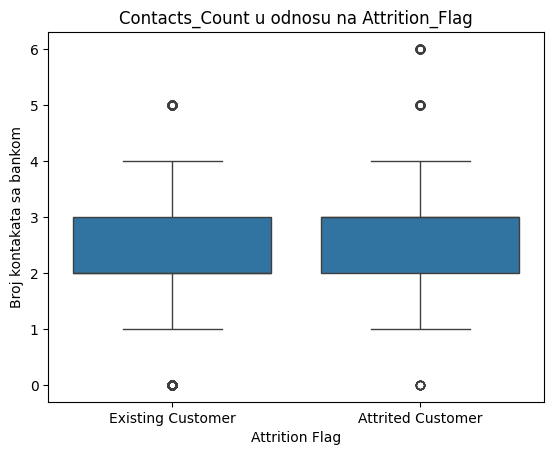

In [87]:
import seaborn as sns

plt.figure()
sns.boxplot(
    x=df['Attrition_Flag_clean'],
    y=df['Contacts_Count_clean']
)
plt.title('Contacts_Count u odnosu na Attrition_Flag')
plt.xlabel('Attrition Flag')
plt.ylabel('Broj kontakata sa bankom')
plt.show()


**Kolona Credit_Limit**

In [88]:
df["Credit_Limit"].apply(type).value_counts()


,count
Credit_Limit,
<class 'str'>,9801
<class 'float'>,326


In [89]:
df["Credit_Limit"].value_counts(dropna=False).sort_index()


,count
Credit_Limit,
-10057.0,1
-10074.0,1
-10100.0,1
-10117.0,1
-10230.0,1
...,...
998326,1
999463,1
9995.0,1


In [90]:
df["Credit_Limit"].astype(str).unique()[:50]


array(['-12691.0', '8256.0', '3418.0', '3313.0', '4716.0', 'nan',
       '34516.0', '29081.0', '590934', '11656.0', '6748.0', '9095.0',
       '-11751.0', '598962', '2436.0#', '294944', '30367.0', '13535.0',
       '-3193.0', '14470.0', '20979.0', '1438.3', '4470.0*', '2492.0X',
       '12217.0', '7768.0', '14784.0#', '10215.0', '-10100.0', '4785.0',
       '933929', '2451.0*', '8923.0', '2650.0', '12555.0', '3520.0',
       '15433.0', '7882.0#', '905679', '6205.0', '17304.0', '3906.0',
       '9830.0', '-34516.0', '980133', '2548.0', '-19458.0', '616748',
       '2622.0', '3171.0'], dtype=object)

In [91]:
import pandas as pd
import numpy as np

df['Credit_Limit_clean'] = df['Credit_Limit'].astype(str).str.replace(r'[^\d.-]', '', regex=True)

df['Credit_Limit_clean'] = pd.to_numeric(df['Credit_Limit_clean'], errors='coerce')


df.loc[df['Credit_Limit_clean'] < 0, 'Credit_Limit_clean'] = np.nan
df.loc[df['Credit_Limit_clean'] > 100000, 'Credit_Limit_clean'] = np.nan

median_limit = df['Credit_Limit_clean'].median()
df['Credit_Limit_clean'] = df['Credit_Limit_clean'].fillna(median_limit)

print("Deskriptivna statistika nakon čišćenja:")
print(df['Credit_Limit_clean'].describe())

Deskriptivna statistika nakon čišćenja:
count    10127.000000
mean      7668.872904
std       8145.050193
min       1438.300000
25%       2909.500000
50%       4537.000000
75%       8302.000000
max      34516.000000
Name: Credit_Limit_clean, dtype: float64


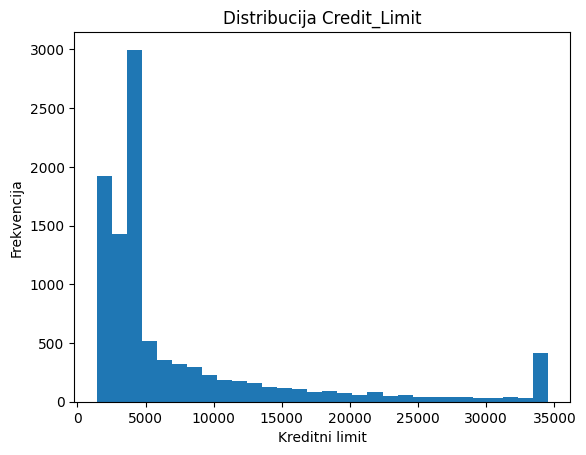

In [92]:
import matplotlib.pyplot as plt

plt.figure()
plt.hist(df['Credit_Limit_clean'], bins=30)
plt.title('Distribucija Credit_Limit')
plt.xlabel('Kreditni limit')
plt.ylabel('Frekvencija')
plt.show()


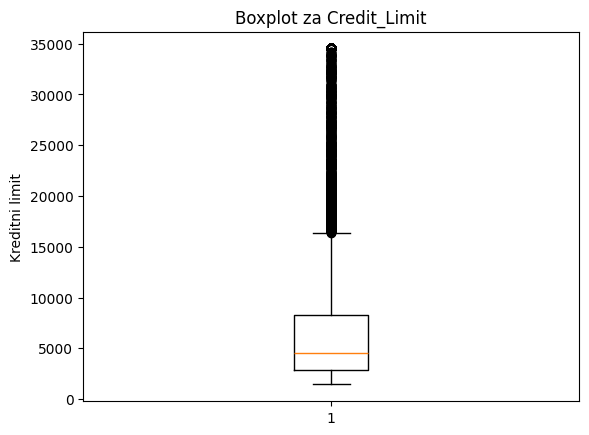

In [93]:
plt.figure()
plt.boxplot(df['Credit_Limit_clean'])
plt.title('Boxplot za Credit_Limit')
plt.ylabel('Kreditni limit')
plt.show()


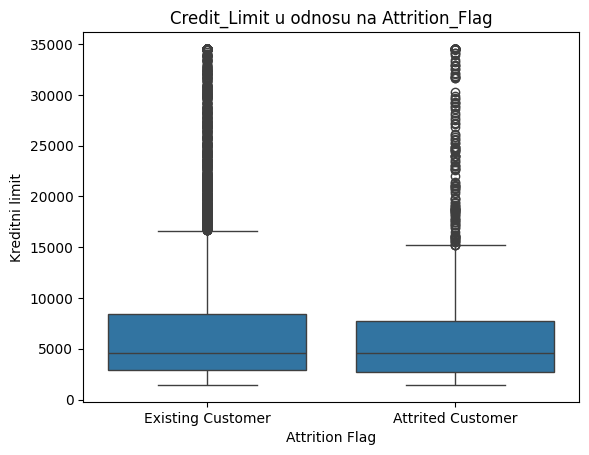

In [94]:
import seaborn as sns

plt.figure()
sns.boxplot(
    x=df['Attrition_Flag_clean'],
    y=df['Credit_Limit_clean']
)
plt.title('Credit_Limit u odnosu na Attrition_Flag')
plt.xlabel('Attrition Flag')
plt.ylabel('Kreditni limit')
plt.show()


**Kolona Total_Revolving_Bal**

In [95]:
df["Total_Revolving_Bal"].apply(type).value_counts()


,count
Total_Revolving_Bal,
<class 'str'>,9819
<class 'float'>,308


In [96]:
df["Total_Revolving_Bal"].value_counts(dropna=False).sort_index()


,count
Total_Revolving_Bal,
-0.0,247
-1002.0,1
-1003.0,1
-1006.0,1
-1010.0,2
...,...
998641,1
999.0,1
999225,1


In [97]:
df["Total_Revolving_Bal"].astype(str).unique()[:20]


array(['777.0', '-864.0', '0.0', '-2517.0', '1247.0', '2264.0', '-1396.0',
       '2517.0X', '1677.0*', '1467.0', '1587.0*', '1666.0', '680.0',
       '972.0#', '2362.0', '1291.0', 'nan', '1157.0*', '1800.0', '680.0#'],
      dtype=object)

In [99]:
import pandas as pd
import numpy as np

df['Total_Revolving_Bal_clean'] = df['Total_Revolving_Bal'].astype(str).str.replace(r'[^\d.-]', '', regex=True)

df['Total_Revolving_Bal_clean'] = pd.to_numeric(df['Total_Revolving_Bal_clean'], errors='coerce')


df.loc[df['Total_Revolving_Bal_clean'] < 0, 'Total_Revolving_Bal_clean'] = np.nan
df.loc[df['Total_Revolving_Bal_clean'] > 50000, 'Total_Revolving_Bal_clean'] = np.nan

median_bal = df['Total_Revolving_Bal_clean'].median()
df['Total_Revolving_Bal_clean'] = df['Total_Revolving_Bal_clean'].fillna(median_bal)

print("Deskriptivna statistika nakon čišćenja:")
print(df['Total_Revolving_Bal_clean'].describe())

Deskriptivna statistika nakon čišćenja:
count    10127.000000
mean      1155.887528
std        739.854987
min          0.000000
25%        725.000000
50%       1249.000000
75%       1637.500000
max       2517.000000
Name: Total_Revolving_Bal_clean, dtype: float64


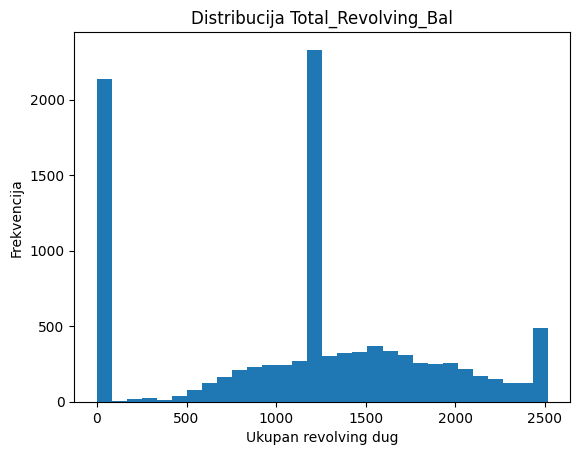

In [100]:
import matplotlib.pyplot as plt

plt.figure()
plt.hist(df['Total_Revolving_Bal_clean'], bins=30)
plt.title('Distribucija Total_Revolving_Bal')
plt.xlabel('Ukupan revolving dug')
plt.ylabel('Frekvencija')
plt.show()


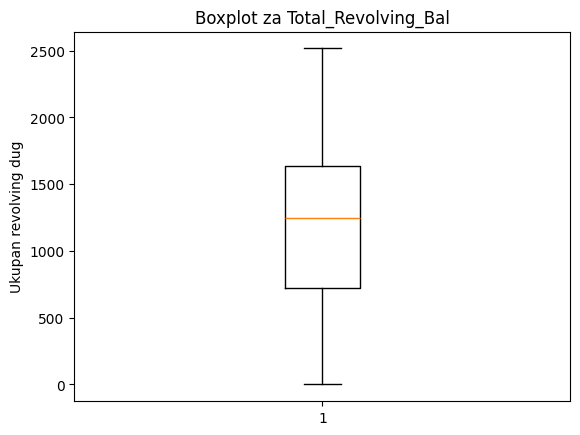

In [101]:
plt.figure()
plt.boxplot(df['Total_Revolving_Bal_clean'])
plt.title('Boxplot za Total_Revolving_Bal')
plt.ylabel('Ukupan revolving dug')
plt.show()


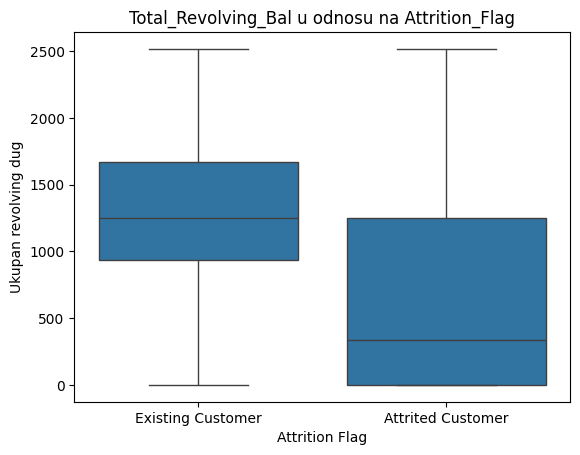

In [102]:
import seaborn as sns

plt.figure()
sns.boxplot(
    x=df['Attrition_Flag_clean'],
    y=df['Total_Revolving_Bal_clean']
)
plt.title('Total_Revolving_Bal u odnosu na Attrition_Flag')
plt.xlabel('Attrition Flag')
plt.ylabel('Ukupan revolving dug')
plt.show()


**Kolona Avg_Open_To_Buy**

In [103]:
df["Avg_Open_To_Buy"].apply(type).value_counts()


,count
Avg_Open_To_Buy,
<class 'str'>,9828
<class 'float'>,299


In [104]:
df["Avg_Open_To_Buy"].value_counts(dropna=False).sort_index()


,count
Avg_Open_To_Buy,
-10002.0,1
-10085.0,1
-1009.0,1
-10104.0,1
-1012.0,1
...,...
9986.0,2
9987.0,1
9995.0,1


In [105]:
df["Avg_Open_To_Buy"].astype(str).unique()[:50]


array(['687017', '815553', '3418.0', '796.0', '4716.0', '2763.0',
       '32252.0', '27685.0', '19835.0', '9979.0X', '5281.0', '7508.0',
       '11751.0', '6881.0', '1756.0', '-3262.0', '28005.0', '12244.0',
       '676.0', '13313.0', '19179.0*', '1438.3', '3790.0', '-932.0',
       '12217.0', '6099.0', '281650', '9205.0', '10100.0', '3423.0',
       '942.0', '761.0', '6406.0', '1160.0', '10859.0', '1606.0', '737.0',
       '15433.0*', '2786.0', '7277.0', '746295', '4001.0', '14787.0',
       '3906.0X', '7775.0', '34516.0', '853.0', '528.0', '18023.0',
       '3518.0'], dtype=object)

In [106]:
import pandas as pd
import numpy as np

df['Avg_Open_To_Buy_clean'] = df['Avg_Open_To_Buy'].astype(str).str.replace(r'[^\d.-]', '', regex=True)

df['Avg_Open_To_Buy_clean'] = pd.to_numeric(df['Avg_Open_To_Buy_clean'], errors='coerce')


df.loc[df['Avg_Open_To_Buy_clean'] < 0, 'Avg_Open_To_Buy_clean'] = np.nan
df.loc[df['Avg_Open_To_Buy_clean'] > 100000, 'Avg_Open_To_Buy_clean'] = np.nan


median_open = df['Avg_Open_To_Buy_clean'].median()
df['Avg_Open_To_Buy_clean'] = df['Avg_Open_To_Buy_clean'].fillna(median_open)

print("Deskriptivna statistika nakon čišćenja:")
print(df['Avg_Open_To_Buy_clean'].describe())

Deskriptivna statistika nakon čišćenja:
count    10127.000000
mean      6587.007811
std       8204.599736
min         10.000000
25%       1601.500000
50%       3473.000000
75%       7254.000000
max      34516.000000
Name: Avg_Open_To_Buy_clean, dtype: float64


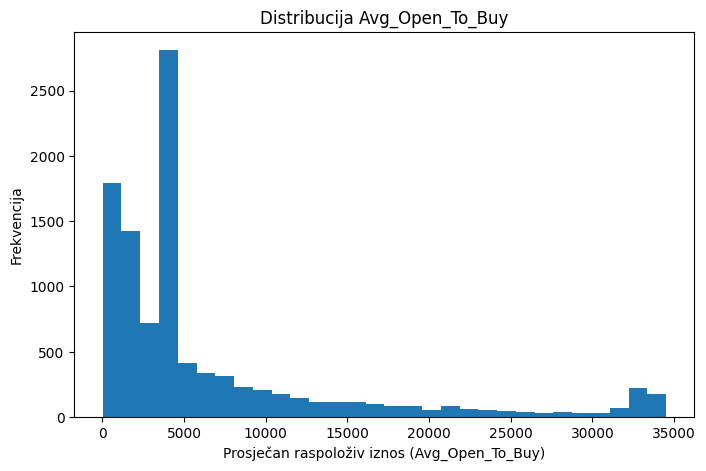

In [107]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.hist(df['Avg_Open_To_Buy_clean'], bins=30)
plt.xlabel('Prosječan raspoloživ iznos (Avg_Open_To_Buy)')
plt.ylabel('Frekvencija')
plt.title('Distribucija Avg_Open_To_Buy')
plt.show()


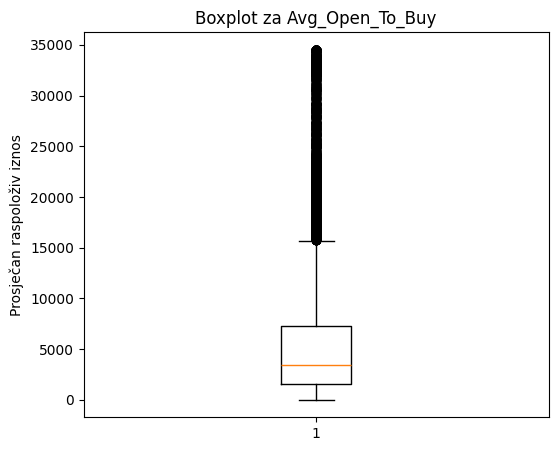

In [108]:
plt.figure(figsize=(6,5))
plt.boxplot(df['Avg_Open_To_Buy_clean'], vert=True)
plt.ylabel('Prosječan raspoloživ iznos')
plt.title('Boxplot za Avg_Open_To_Buy')
plt.show()


<Figure size 700x500 with 0 Axes>

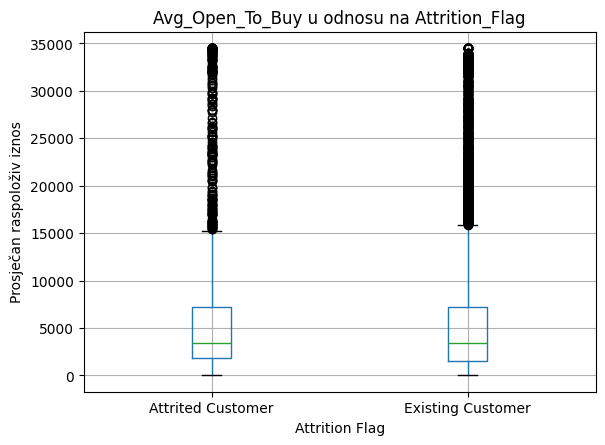

In [109]:
plt.figure(figsize=(7,5))
df.boxplot(
    column='Avg_Open_To_Buy_clean',
    by='Attrition_Flag_clean'
)
plt.xlabel('Attrition Flag')
plt.ylabel('Prosječan raspoloživ iznos')
plt.title('Avg_Open_To_Buy u odnosu na Attrition_Flag')
plt.suptitle('')
plt.show()


**Kolona Total_Amt_Chng_Q4_Q1**

In [110]:
df["Total_Amt_Chng_Q4_Q1"].apply(type).value_counts()


,count
Total_Amt_Chng_Q4_Q1,
<class 'str'>,9850
<class 'float'>,277


In [111]:
df["Total_Amt_Chng_Q4_Q1"].value_counts(dropna=False).sort_index()


,count
Total_Amt_Chng_Q4_Q1,
-0.0,1
-0.175,1
-0.2,1
-0.236,1
-0.242,1
...,...
997740,1
997965,1
998145,1


In [112]:
df["Total_Amt_Chng_Q4_Q1"].astype(str).unique()[:50]


array(['nan', '2.594', '1.405', '2.175', '1.376X', '1.975X', '2.204',
       '3.355', '1.524', '0.831', '932117', '3.397', '1.163', '1.19',
       '1.707', '1.708', '0.653', '-1.831', '-0.966', '542415', '1.047',
       '789451', '0.573*', '1.075', '0.797', '-0.921', '0.843', '0.525',
       '0.739', '0.977', '1.323*', '1.726', '1.75', '0.519#', '-0.51',
       '0.865', '1.32', '1.052', '1.042', '225112', '1.449', '1.214',
       '0.977X', '1.621X', '2.316#', '856665', '167087', '0.624', '1.321',
       '373144'], dtype=object)

In [113]:
import pandas as pd
import numpy as np

df['Total_Amt_Chng_clean'] = df['Total_Amt_Chng_Q4_Q1'].astype(str).str.replace(r'[^\d.-]', '', regex=True)

df['Total_Amt_Chng_clean'] = pd.to_numeric(df['Total_Amt_Chng_clean'], errors='coerce')


df.loc[df['Total_Amt_Chng_clean'] < 0, 'Total_Amt_Chng_clean'] = np.nan
df.loc[df['Total_Amt_Chng_clean'] > 10, 'Total_Amt_Chng_clean'] = np.nan


median_change = df['Total_Amt_Chng_clean'].median()
df['Total_Amt_Chng_clean'] = df['Total_Amt_Chng_clean'].fillna(median_change)

print("Deskriptivna statistika nakon čišćenja:")
print(df['Total_Amt_Chng_clean'].describe())

Deskriptivna statistika nakon čišćenja:
count    10127.000000
mean         0.755020
std          0.196356
min          0.000000
25%          0.665000
50%          0.737000
75%          0.819000
max          3.397000
Name: Total_Amt_Chng_clean, dtype: float64


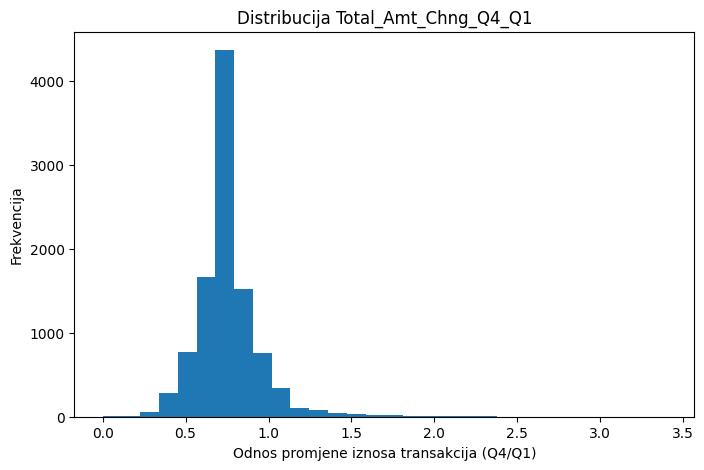

In [114]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.hist(df['Total_Amt_Chng_clean'], bins=30)
plt.xlabel('Odnos promjene iznosa transakcija (Q4/Q1)')
plt.ylabel('Frekvencija')
plt.title('Distribucija Total_Amt_Chng_Q4_Q1')
plt.show()


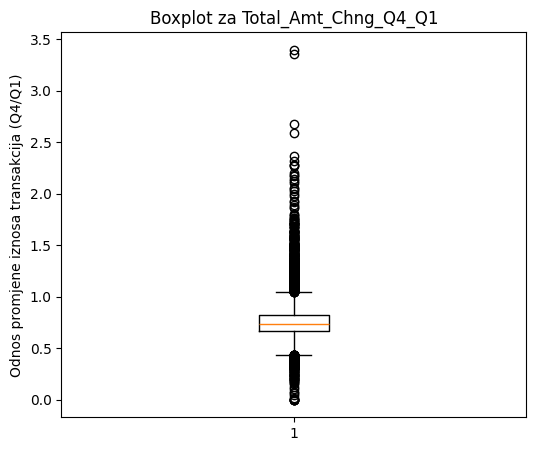

In [115]:
plt.figure(figsize=(6,5))
plt.boxplot(df['Total_Amt_Chng_clean'], vert=True)
plt.ylabel('Odnos promjene iznosa transakcija (Q4/Q1)')
plt.title('Boxplot za Total_Amt_Chng_Q4_Q1')
plt.show()


<Figure size 700x500 with 0 Axes>

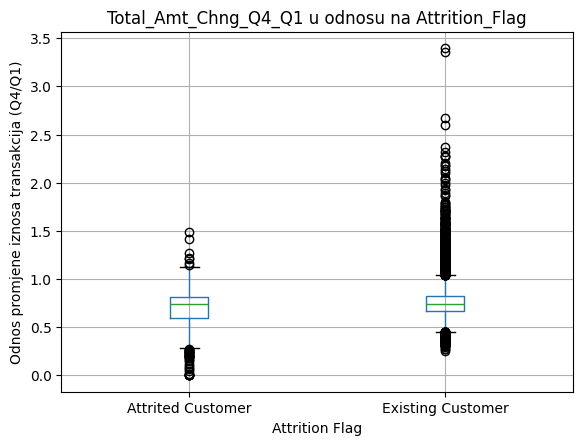

In [116]:
plt.figure(figsize=(7,5))
df.boxplot(
    column='Total_Amt_Chng_clean',
    by='Attrition_Flag_clean'
)
plt.xlabel('Attrition Flag')
plt.ylabel('Odnos promjene iznosa transakcija (Q4/Q1)')
plt.title('Total_Amt_Chng_Q4_Q1 u odnosu na Attrition_Flag')
plt.suptitle('')
plt.show()


**Kolona Total_Trans_Amt**

In [117]:
df["Total_Trans_Amt"].apply(type).value_counts()


,count
Total_Trans_Amt,
<class 'str'>,9817
<class 'float'>,310


In [118]:
df["Total_Trans_Amt"].value_counts(dropna=False).sort_index()


,count
Total_Trans_Amt,
-1015.0,1
-10201.0,1
-1052.0,1
-1102.0,2
-1110.0,1
...,...
9980.0,1
998623,1
999.0,1


In [119]:
df["Total_Trans_Amt"].astype(str).unique()[:50]


array(['1144.0', '1291.0', '1887.0', '1171.0', '-816.0', '1088.0',
       '1330.0', '1538.0', '1350.0', '1441.0', '1201.0', '1314.0',
       '1539.0', '1311.0', '-1570.0', '-1348.0', '1671.0', '1028.0',
       '-1336.0', '1207.0#', '1178.0', '692.0', '931.0#', '1126.0',
       '1110.0', '1051.0', '-1197.0', '1904.0', '916642', '1045.0',
       '1038.0', '1596.0', '1589.0', '1411.0', '1407.0', '862000',
       '966.0', '1464.0', '704.0X', '1109.0', '-1347.0', '1756.0',
       '1756.0X', '1042.0', '1444.0', '1741.0', '1719.0', '-1217.0',
       '263945', '1878.0'], dtype=object)

In [121]:
import pandas as pd
import numpy as np

df['Total_Trans_Amt_clean'] = df['Total_Trans_Amt'].astype(str).str.replace(r'[^\d.-]', '', regex=True)

df['Total_Trans_Amt_clean'] = pd.to_numeric(df['Total_Trans_Amt_clean'], errors='coerce')


df.loc[df['Total_Trans_Amt_clean'] < 0, 'Total_Trans_Amt_clean'] = np.nan
df.loc[df['Total_Trans_Amt_clean'] > 50000, 'Total_Trans_Amt_clean'] = np.nan


median_amt = df['Total_Trans_Amt_clean'].median()
df['Total_Trans_Amt_clean'] = df['Total_Trans_Amt_clean'].fillna(median_amt)

print("Deskriptivna statistika nakon čišćenja:")
print(df['Total_Trans_Amt_clean'].describe())

Deskriptivna statistika nakon čišćenja:
count    10127.000000
mean      4294.708206
std       2985.454173
min        510.000000
25%       2530.000000
50%       3899.000000
75%       4503.000000
max      17744.000000
Name: Total_Trans_Amt_clean, dtype: float64


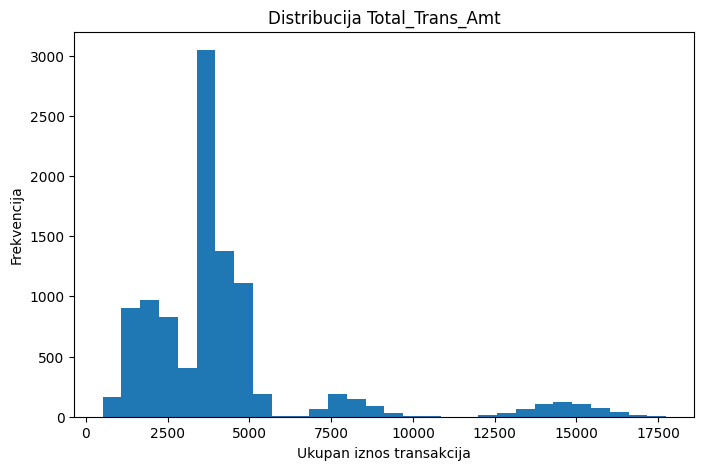

In [122]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.hist(df['Total_Trans_Amt_clean'], bins=30)
plt.xlabel('Ukupan iznos transakcija')
plt.ylabel('Frekvencija')
plt.title('Distribucija Total_Trans_Amt')
plt.show()


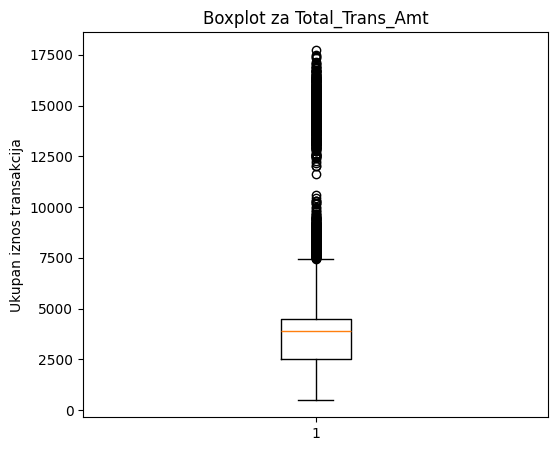

In [123]:
plt.figure(figsize=(6,5))
plt.boxplot(df['Total_Trans_Amt_clean'], vert=True)
plt.ylabel('Ukupan iznos transakcija')
plt.title('Boxplot za Total_Trans_Amt')
plt.show()


<Figure size 700x500 with 0 Axes>

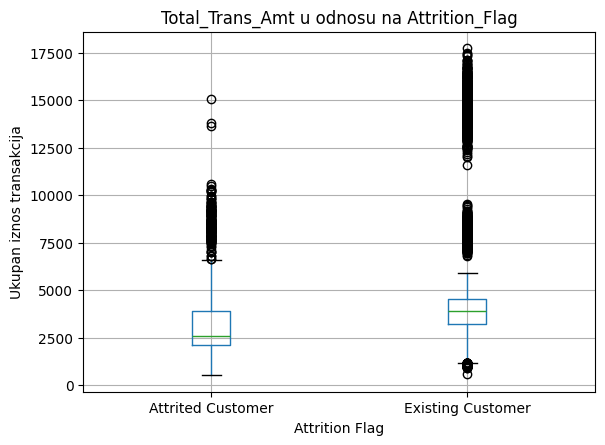

In [124]:
plt.figure(figsize=(7,5))
df.boxplot(
    column='Total_Trans_Amt_clean',
    by='Attrition_Flag_clean'
)
plt.xlabel('Attrition Flag')
plt.ylabel('Ukupan iznos transakcija')
plt.title('Total_Trans_Amt u odnosu na Attrition_Flag')
plt.suptitle('')
plt.show()


**Kolona Total_Trans_Ct**

In [125]:
df["Total_Trans_Ct"].apply(type).value_counts()


,count
Total_Trans_Ct,
<class 'str'>,9817
<class 'float'>,310


In [126]:
df["Total_Trans_Ct"].value_counts(dropna=False).sort_index()


,count
Total_Trans_Ct,
-100.0,8
-101.0,4
-102.0,2
-103.0,3
-104.0,1
...,...
993165,1
994712,1
996567,1


In [127]:
df["Total_Trans_Ct"].astype(str).unique()[:100]


array(['42.0X', '624162', '20.0', '28.0', '24.0', '31.0', '36.0', '32.0',
       '500391', '26.0', '17.0', '33.0', '29.0', '27.0', '837318', '21.0',
       '30.0', '-16.0', '18.0', '23.0', '22.0*', '40.0', '38.0*', '25.0',
       '492987', '629280', '-24.0', '43.0', '37.0', '-22.0', '28.0#',
       '830820', '382243', 'nan', '-27.0', '320065', '35.0', '-15.0',
       '-25.0', '27.0X', '-33.0', '15.0*', '755619', '17.0*', '600541',
       '41.0', '36.0X', '-21.0', '125082', '57.0', '12.0X', '758490',
       '-31.0', '14.0X', '-29.0', '34.0', '440036', '-32.0', '42.0#',
       '19.0', '22.0', '109240', '33.0X', '487495', '236406', '21.0*',
       '44.0', '31.0#', '13.0', '38.0', '596394', '42.0', '30.0*', '16.0',
       '26.0X', '10.0', '39.0', '567572', '24.0*', '30.0X', '53.0',
       '47.0', '50.0', '-28.0', '-52.0', '234607', '390401', '37.0X',
       '48.0', '467522', '32.0X', '816267', '12.0', '25.0#', '849818',
       '15.0', '-26.0', '475922', '171816', '838191'], dtype=object)

In [128]:
import pandas as pd
import numpy as np

df['Total_Trans_Ct_clean'] = df['Total_Trans_Ct'].astype(str).str.replace(r'[^\d.-]', '', regex=True)

df['Total_Trans_Ct_clean'] = pd.to_numeric(df['Total_Trans_Ct_clean'], errors='coerce')


df.loc[df['Total_Trans_Ct_clean'] < 0, 'Total_Trans_Ct_clean'] = np.nan
df.loc[df['Total_Trans_Ct_clean'] > 2000, 'Total_Trans_Ct_clean'] = np.nan


median_ct = df['Total_Trans_Ct_clean'].median()
df['Total_Trans_Ct_clean'] = df['Total_Trans_Ct_clean'].fillna(median_ct)

print("Deskriptivna statistika nakon čišćenja:")
print(df['Total_Trans_Ct_clean'].describe())

Deskriptivna statistika nakon čišćenja:
count    10127.000000
mean        65.292387
std         20.641201
min         10.000000
25%         52.000000
50%         67.000000
75%         76.000000
max        139.000000
Name: Total_Trans_Ct_clean, dtype: float64


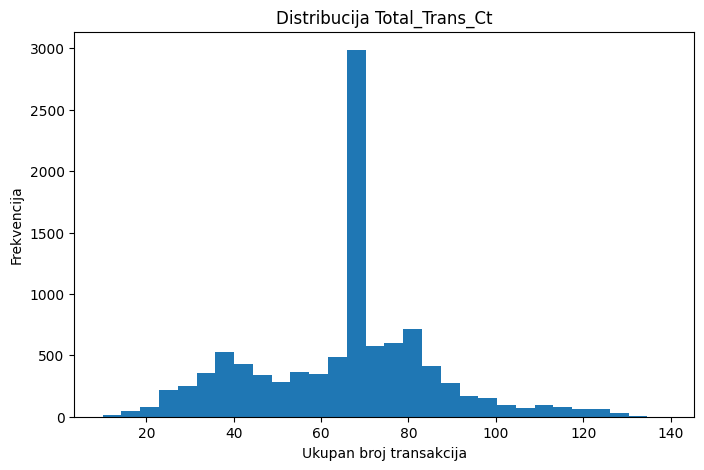

In [129]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.hist(df['Total_Trans_Ct_clean'], bins=30)
plt.xlabel('Ukupan broj transakcija')
plt.ylabel('Frekvencija')
plt.title('Distribucija Total_Trans_Ct')
plt.show()


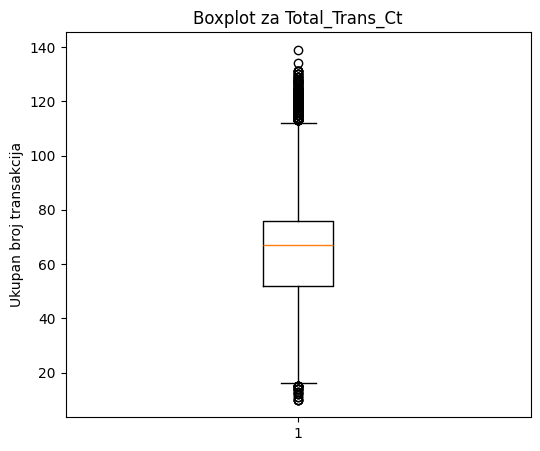

In [130]:
plt.figure(figsize=(6,5))
plt.boxplot(df['Total_Trans_Ct_clean'], vert=True)
plt.ylabel('Ukupan broj transakcija')
plt.title('Boxplot za Total_Trans_Ct')
plt.show()


<Figure size 700x500 with 0 Axes>

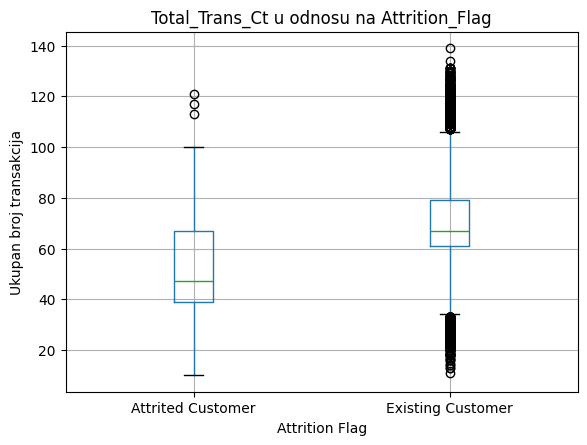

In [131]:
plt.figure(figsize=(7,5))
df.boxplot(
    column='Total_Trans_Ct_clean',
    by='Attrition_Flag_clean'
)
plt.xlabel('Attrition Flag')
plt.ylabel('Ukupan broj transakcija')
plt.title('Total_Trans_Ct u odnosu na Attrition_Flag')
plt.suptitle('')
plt.show()


**Kolona Total_Ct_Chng_Q4_Q1**

In [132]:
df["Total_Ct_Chng_Q4_Q1"].apply(type).value_counts()


,count
Total_Ct_Chng_Q4_Q1,
<class 'str'>,9837
<class 'float'>,290


In [133]:
df["Total_Ct_Chng_Q4_Q1"].value_counts(dropna=False).sort_index()


,count
Total_Ct_Chng_Q4_Q1,
-0.053,1
-0.077,1
-0.176,1
-0.207,1
-0.222,1
...,...
996409,1
997827.0,1
998057,1


In [134]:
df["Total_Ct_Chng_Q4_Q1"].astype(str).unique()[:100]

array(['1.625', '3.714#', '2.333', '2.5', '0.846', '0.722', '-0.714',
       '1.182#', '437215', '0.68', '1.364', '3.25', '2.0', '0.611', '1.7',
       '0.929', '1.143', '0.909', '655326', '1.571', '-0.353', '0.75',
       '0.833', '1.3#', '-1.0', '998057', '2.571', '1.6', '1.667', '1.0',
       '0.483X', '1.176', '1.2X', '0.556', '558869', '-0.474', '1.2',
       '0.917', '911764', '0.588', '0.8', '0.6', '172356', '1.923',
       '0.25', '0.364', '1.417X', '1.083', '1.25', '0.833X', '0.5',
       '1.154', '-0.733', '-0.917', '0.667', '2.4', '1.05*', '0.286',
       '0.4', '0.522', '1.182', '0.435', '-1.875', '544495', '0.353',
       '1.412', '0.526', '0.714#', '0.818', '2.0X', '0.667X', '1.8',
       '1.636#', '1.333', '2.182', '129123', '0.933*', '1.222', '-0.882',
       '622706', '402702', '0.727', '0.385#', '1.5', '0.789', '0.542',
       '1.1', '-1.095', '0.824', '-0.391', '168123', '3.0', '674631',
       '1.118', '0.786X', '1.0#', '0.625', '-1.533', '0.382', '0.355'],
      dt

In [135]:
import pandas as pd
import numpy as np

df['Total_Ct_Chng_clean'] = df['Total_Ct_Chng_Q4_Q1'].astype(str).str.replace(r'[^\d.-]', '', regex=True)

df['Total_Ct_Chng_clean'] = pd.to_numeric(df['Total_Ct_Chng_clean'], errors='coerce')



df.loc[df['Total_Ct_Chng_clean'] < 0, 'Total_Ct_Chng_clean'] = np.nan
df.loc[df['Total_Ct_Chng_clean'] > 10, 'Total_Ct_Chng_clean'] = np.nan


median_val = df['Total_Ct_Chng_clean'].median()
df['Total_Ct_Chng_clean'] = df['Total_Ct_Chng_clean'].fillna(median_val)

print("Deskriptivna statistika nakon čišćenja:")
print(df['Total_Ct_Chng_clean'].describe())

Deskriptivna statistika nakon čišćenja:
count    10127.000000
mean         0.709383
std          0.215126
min          0.000000
25%          0.618000
50%          0.700000
75%          0.780000
max          3.714000
Name: Total_Ct_Chng_clean, dtype: float64


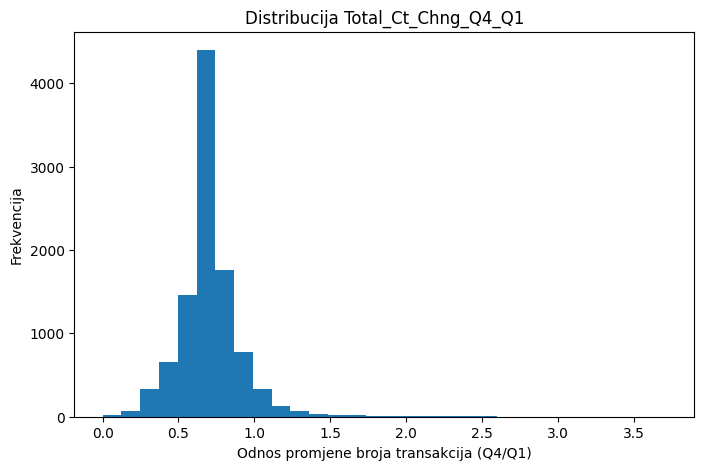

In [136]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.hist(df['Total_Ct_Chng_clean'], bins=30)
plt.title('Distribucija Total_Ct_Chng_Q4_Q1')
plt.xlabel('Odnos promjene broja transakcija (Q4/Q1)')
plt.ylabel('Frekvencija')
plt.show()


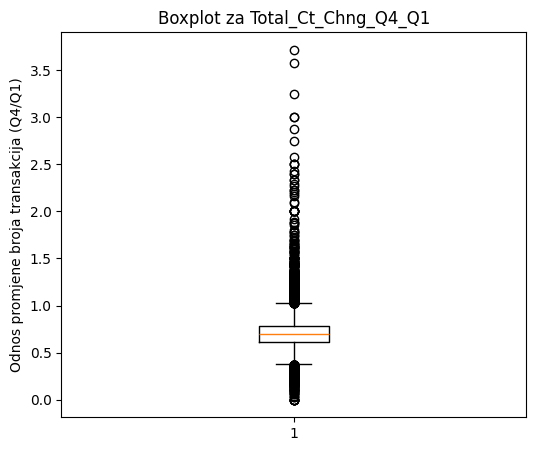

In [137]:
plt.figure(figsize=(6,5))
plt.boxplot(df['Total_Ct_Chng_clean'])
plt.title('Boxplot za Total_Ct_Chng_Q4_Q1')
plt.ylabel('Odnos promjene broja transakcija (Q4/Q1)')
plt.show()


<Figure size 800x500 with 0 Axes>

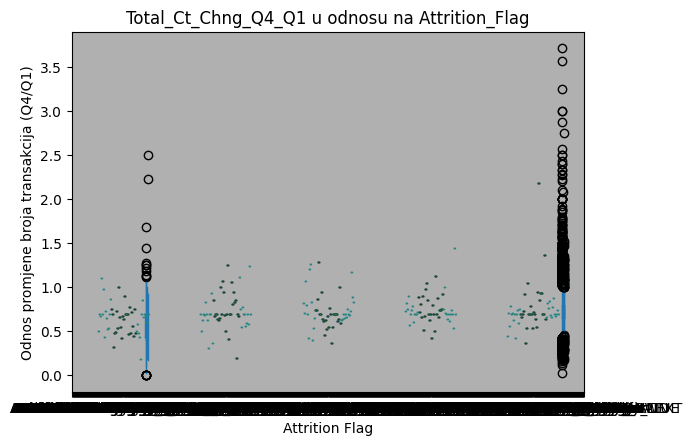

In [139]:
plt.figure(figsize=(8,5))
df.boxplot(column='Total_Ct_Chng_clean', by='Attrition_Flag')
plt.title('Total_Ct_Chng_Q4_Q1 u odnosu na Attrition_Flag')
plt.suptitle('')
plt.xlabel('Attrition Flag')
plt.ylabel('Odnos promjene broja transakcija (Q4/Q1)')
plt.show()


**Kolona Avg_Utilization_Ratio**

In [140]:
df["Avg_Utilization_Ratio"].apply(type).value_counts()


,count
Avg_Utilization_Ratio,
<class 'str'>,9845
<class 'float'>,282


In [141]:
df["Avg_Utilization_Ratio"].value_counts(dropna=False).sort_index()


,count
Avg_Utilization_Ratio,
-0.0,244
-0.006,1
-0.021,3
-0.022,1
-0.023,1
...,...
994033,1
994202,1
996038,1


In [142]:
df["Avg_Utilization_Ratio"].astype(str).unique()[:100]


array(['0.061', '0.105', '0.0X', '0.76', '0.0*', '0.311', '145750',
       '-0.048', '0.113', '0.144', '0.217', '0.174', '0.0', '0.195',
       '-0.279', '0.23#', '0.078', '0.095', '0.788', '288057', '-0.086',
       '0.152', '0.626', '0.215#', '0.093', '0.099', '-0.0', '0.285',
       '0.658', 'nan', '0.282*', '0.562', '0.135', '0.544', '0.757',
       '0.241', '0.077', '0.018*', '0.355X', '0.145', '0.209', '0.793X',
       '0.074', '0.259', '0.591', '-0.562', '0.687*', '0.127', '0.667',
       '220583', '-0.422', '0.156', '0.525', '0.587', '0.211', '0.088',
       '0.111', '0.044', '0.276', '0.704', '0.656', '0.053', '419460',
       '844034', '-0.698', '0.067', '0.079', '0.287', '0.36', '-0.256',
       '0.719', '0.066', '0.198', '810799', '0.14', '-0.035', '0.619',
       '0.108', '746551', '0.062#', '0.765X', '-0.963', '0.524', '0.347',
       '0.45', '0.232', '0.299', '0.085', '0.059', '393397', '0.62',
       '0.027#', '897166', '0.058*', '0.223', '0.057', '0.095X', '511937',
  

In [143]:
import pandas as pd
import numpy as np

df['Avg_Utilization_Ratio_clean'] = df['Avg_Utilization_Ratio'].astype(str).str.replace(r'[^\d.-]', '', regex=True)

df['Avg_Utilization_Ratio_clean'] = pd.to_numeric(df['Avg_Utilization_Ratio_clean'], errors='coerce')


df.loc[df['Avg_Utilization_Ratio_clean'] < 0, 'Avg_Utilization_Ratio_clean'] = np.nan
df.loc[df['Avg_Utilization_Ratio_clean'] > 1, 'Avg_Utilization_Ratio_clean'] = np.nan

median_util = df['Avg_Utilization_Ratio_clean'].median()
df['Avg_Utilization_Ratio_clean'] = df['Avg_Utilization_Ratio_clean'].fillna(median_util)

print("Deskriptivna statistika nakon čišćenja:")
print(df['Avg_Utilization_Ratio_clean'].describe())

Deskriptivna statistika nakon čišćenja:
count    10127.000000
mean         0.245198
std          0.249181
min          0.000000
25%          0.048000
50%          0.163000
75%          0.386000
max          0.999000
Name: Avg_Utilization_Ratio_clean, dtype: float64


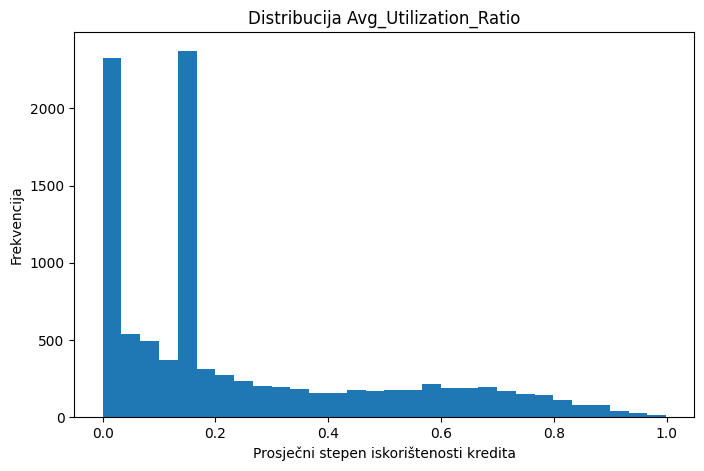

In [144]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.hist(df['Avg_Utilization_Ratio_clean'], bins=30)
plt.xlabel('Prosječni stepen iskorištenosti kredita')
plt.ylabel('Frekvencija')
plt.title('Distribucija Avg_Utilization_Ratio')
plt.show()


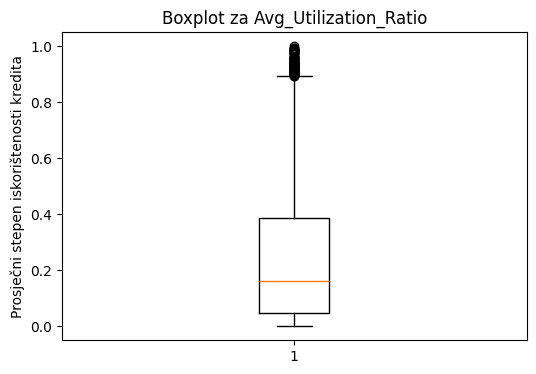

In [145]:
plt.figure(figsize=(6,4))
plt.boxplot(df['Avg_Utilization_Ratio_clean'], vert=True)
plt.ylabel('Prosječni stepen iskorištenosti kredita')
plt.title('Boxplot za Avg_Utilization_Ratio')
plt.show()


<Figure size 700x500 with 0 Axes>

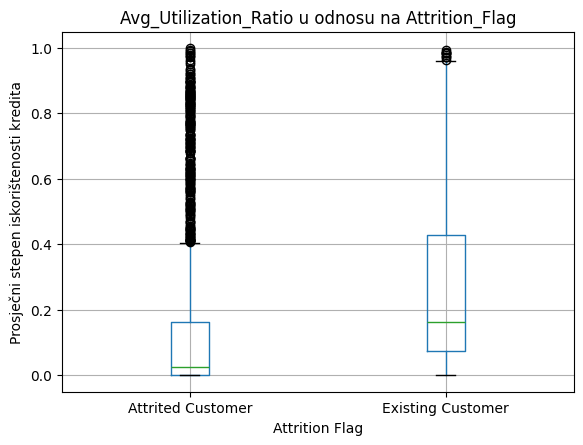

In [146]:
plt.figure(figsize=(7,5))
df.boxplot(
    column='Avg_Utilization_Ratio_clean',
    by='Attrition_Flag_clean'
)
plt.xlabel('Attrition Flag')
plt.ylabel('Prosječni stepen iskorištenosti kredita')
plt.title('Avg_Utilization_Ratio u odnosu na Attrition_Flag')
plt.suptitle('')
plt.show()


In [147]:
cols_to_drop = [
    'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1',
    'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2'
]

df = df.drop(columns=cols_to_drop, errors='ignore')

print("Kolone uspješno obrisane.")

Kolone uspješno obrisane.


In [148]:
print(df['Account_Status'].head())
print(df['Account_Status'].value_counts(dropna=False))

print(df['Last_Login_Days'].head())

0     Pending
1    Inactive
2    Inactive
3      Active
4     Pending
Name: Account_Status, dtype: object
Account_Status
Inactive     2583
Active       2575
Suspended    2496
Pending      2473
Name: count, dtype: int64
0    219
1     98
2    303
3    115
4      1
Name: Last_Login_Days, dtype: int64


**Kolone Account_Status i Last_Login_Days**

In [149]:
columns_to_drop = ['Account_Status', 'Last_Login_Days']

df = df.drop(columns=columns_to_drop, errors='ignore')

print("Kolone su obrisane.")
print("Trenutne kolone u datasetu:", df.columns.tolist())

Kolone su obrisane.
Trenutne kolone u datasetu: ['CLIENTNUM', 'Attrition_Flag', 'Customer_Age', 'Gender', 'Dependent_count', 'Education_Level', 'Marital_Status', 'Income_Category', 'Card_Category', 'Months_on_book', 'Total_Relationship_Count', 'Months_Inactive_12_mon', 'Contacts_Count_12_mon', 'Credit_Limit', 'Total_Revolving_Bal', 'Avg_Open_To_Buy', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt', 'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio', 'Attrition_Flag_clean', 'Attrition_Flag_Encoded', 'Customer_Age_clean', 'Gender_clean', 'Gender_Encoded', 'Dependent_count_clean', 'Education_Level_clean', 'Marital_Status_clean', 'Income_Category_clean', 'Card_Category_clean', 'Months_on_book_clean', 'Total_Relationship_Count_clean', 'Months_Inactive_clean', 'Contacts_Count_clean', 'Credit_Limit_clean', 'Total_Revolving_Bal_clean', 'Avg_Open_To_Buy_clean', 'Total_Amt_Chng_clean', 'Total_Trans_Amt_clean', 'Total_Trans_Ct_clean', 'Total_Ct_Chng_clean', 'Avg_Utilization_Ratio_clean']


In [150]:
df.to_csv("clean_dataset.csv", index=False)


In [151]:
df_numeric = df.select_dtypes(include=['int64', 'float64'])

corr_matrix = df_numeric.corr()

corr_matrix


,Attrition_Flag_Encoded,Customer_Age_clean,Gender_Encoded,Dependent_count_clean,Months_on_book_clean,Total_Relationship_Count_clean,Months_Inactive_clean,Contacts_Count_clean,Credit_Limit_clean,Total_Revolving_Bal_clean,Avg_Open_To_Buy_clean,Total_Amt_Chng_clean,Total_Trans_Amt_clean,Total_Trans_Ct_clean,Total_Ct_Chng_clean,Avg_Utilization_Ratio_clean
Attrition_Flag_Encoded,1.000000,0.007975,-0.034305,0.015104,0.011900,-0.123664,0.131749,0.179656,-0.018716,-0.241660,0.008741,-0.109126,-0.142212,-0.318589,-0.252640,-0.155496
Customer_Age_clean,0.007975,1.000000,-0.006840,-0.098988,0.601201,0.003192,0.042736,-0.022285,-0.000552,0.014706,0.003859,-0.046345,-0.024375,-0.042949,-0.012432,-0.000961
Gender_Encoded,-0.034305,-0.006840,1.000000,0.009592,-0.002940,-0.003156,-0.008527,0.039999,0.357127,0.020532,0.353730,0.017343,0.019316,-0.061730,-0.001936,-0.204329
Dependent_count_clean,0.015104,-0.098988,0.009592,1.000000,-0.084122,-0.037356,0.000038,-0.026486,0.054779,0.001670,0.048981,-0.031423,0.013463,0.032046,-0.000400,-0.029709
Months_on_book_clean,0.011900,0.601201,-0.002940,-0.084122,1.000000,-0.002069,0.060883,-0.014084,0.003126,0.009324,0.000749,-0.038179,-0.026600,-0.031953,-0.011345,0.000280
Total_Relationship_Count_clean,-0.123664,0.003192,-0.003156,-0.037356,-0.002069,1.000000,0.003463,0.042687,-0.057009,0.013478,-0.056480,0.038879,-0.271842,-0.194166,0.029413,0.052109
Months_Inactive_clean,0.131749,0.042736,-0.008527,0.000038,0.060883,0.003463,1.000000,0.016109,-0.003940,-0.036255,-0.009349,-0.012393,-0.028180,-0.021881,-0.021657,-0.006608
Contacts_Count_clean,0.179656,-0.022285,0.039999,-0.026486,-0.014084,0.042687,0.016109,1.000000,0.018282,-0.046890,0.020944,-0.019787,-0.081144,-0.108662,-0.081073,-0.048946
Credit_Limit_clean,-0.018716,-0.000552,0.357127,0.054779,0.003126,-0.057009,-0.003940,0.018282,1.000000,0.024464,0.735207,-0.004420,0.121262,0.050035,-0.000290,-0.350478
Total_Revolving_Bal_clean,-0.241660,0.014706,0.020532,0.001670,0.009324,0.013478,-0.036255,-0.046890,0.024464,1.000000,-0.046542,0.043431,0.043949,0.057608,0.076698,0.511321


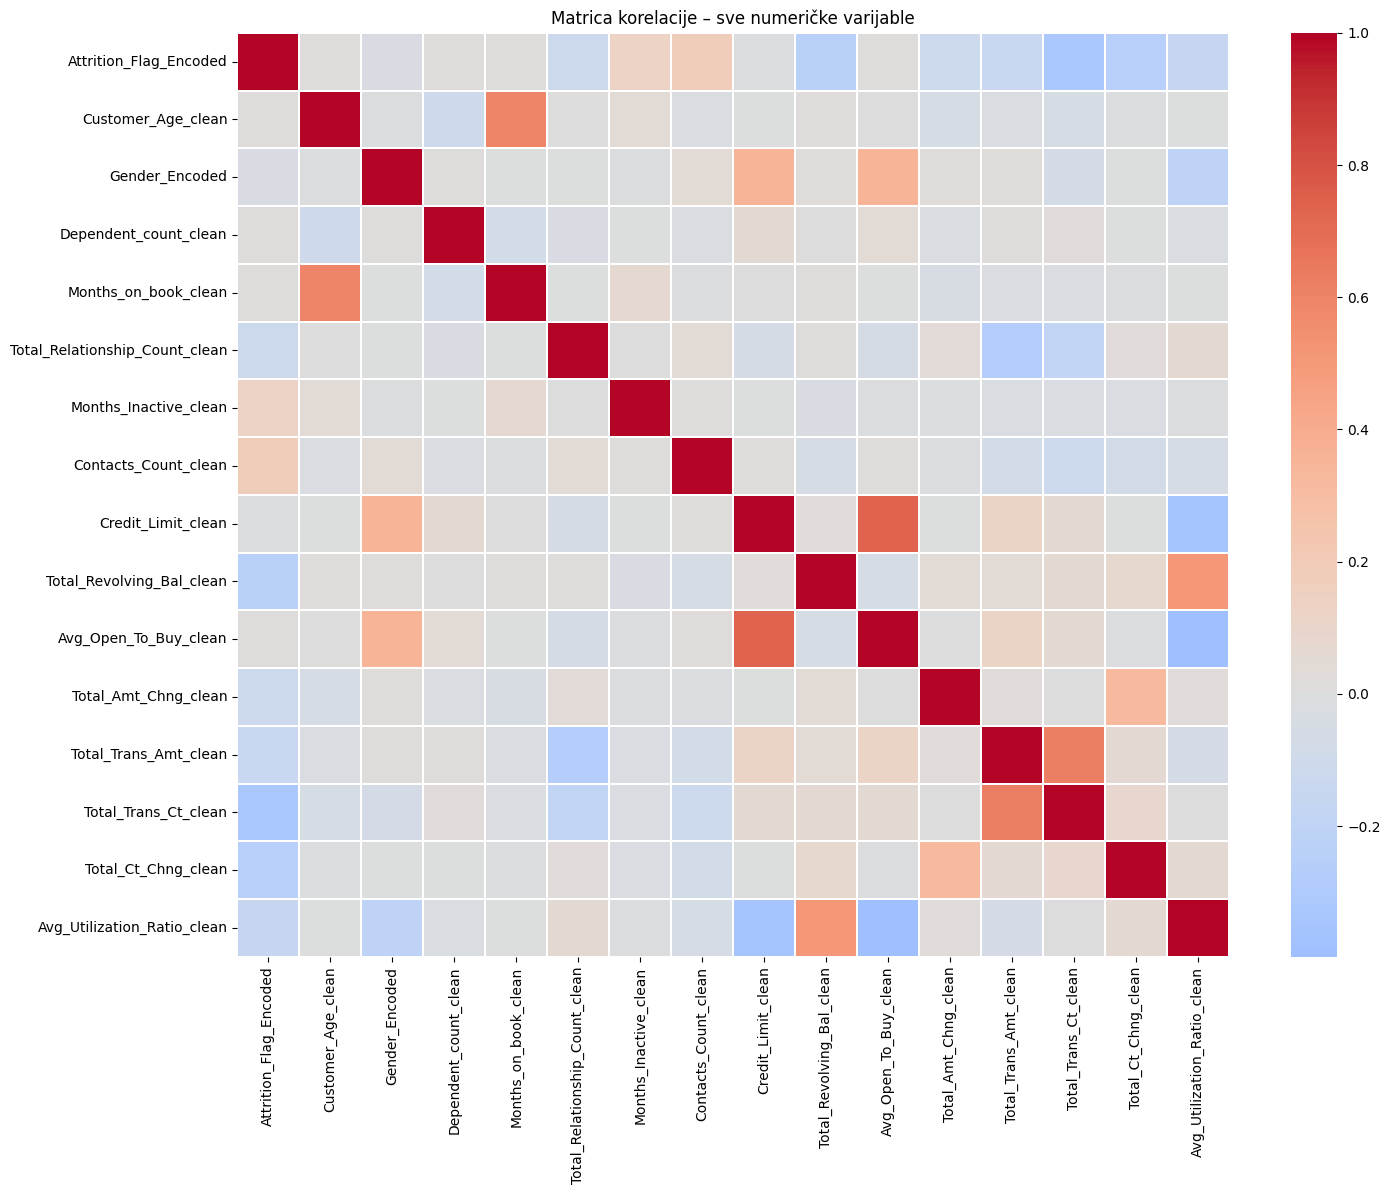

In [152]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 12))
sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    center=0,
    linewidths=0.3
)
plt.title("Matrica korelacije – sve numeričke varijable")
plt.show()


In [153]:
clean_cols = [c for c in df.columns if c.endswith('_clean')]
df[clean_cols].head()

,Attrition_Flag_clean,Customer_Age_clean,Gender_clean,Dependent_count_clean,Education_Level_clean,Marital_Status_clean,Income_Category_clean,Card_Category_clean,Months_on_book_clean,Total_Relationship_Count_clean,Months_Inactive_clean,Contacts_Count_clean,Credit_Limit_clean,Total_Revolving_Bal_clean,Avg_Open_To_Buy_clean,Total_Amt_Chng_clean,Total_Trans_Amt_clean,Total_Trans_Ct_clean,Total_Ct_Chng_clean,Avg_Utilization_Ratio_clean
0,Existing Customer,45.0,M,3.0,High School,Married,$60K - $80K,Blue,39.0,4.0,1.0,3.0,4537.0,777.0,3473.0,0.737,1144.0,42.0,1.625,0.061
1,Existing Customer,49.0,F,5.0,Graduate,Single,Less than $40K,Blue,44.0,6.0,1.0,2.0,8256.0,1249.0,3473.0,0.737,1291.0,67.0,3.714,0.105
2,Existing Customer,46.0,M,3.0,Graduate,Married,$80K - $120K,Blue,36.0,4.0,1.0,2.0,3418.0,0.0,3418.0,2.594,1887.0,20.0,2.333,0.000
3,Existing Customer,46.0,F,4.0,High School,Unknown,Less than $40K,Blue,34.0,3.0,4.0,2.0,3313.0,1249.0,796.0,1.405,1171.0,20.0,2.333,0.760
4,Existing Customer,46.0,M,3.0,Uneducated,Married,$60K - $80K,Blue,36.0,5.0,2.0,2.0,4716.0,0.0,4716.0,2.175,3899.0,28.0,2.500,0.000
